<a href="https://colab.research.google.com/github/DDDBBBPPP/ML-Morningstar/blob/main/proyecto_fondos_morningstar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ¿Cuántas estrellas tendría este fondo? Un "Morningstar casero" con Machine Learning

**Proyecto completo de Machine Learning** · Máster de FP en Inteligencia Artificial y Big Data

**Autor:** _David Bellón Payer_

**Vídeo explicativo:** _https://youtu.be/Lc6Sqdf-59Q_

**Datos:** [US Funds dataset from Yahoo Finance](https://www.kaggle.com/datasets/stefanoleone992/mutual-funds-and-etfs) (Kaggle), archivo [`MutualFunds.csv`](https://www.kaggle.com/datasets/stefanoleone992/mutual-funds-and-etfs?select=MutualFunds.csv)

---

### Índice
1. Obtención de datos
2. Descripción de los datos
3. Exploración y visualización
4. Exposición del objetivo
5. Preparación de los datos
6. Entrenamiento de modelos y rendimiento
7. Conclusiones

## Imagen general: el problema

Cuando alguien busca un fondo de inversión, una de las primeras cosas que ve son sus **estrellas de Morningstar**, de 1 a 5. Mucha gente elige fondo casi solo por eso.

Morningstar da las estrellas comparando cada fondo con los de **su misma categoría**: mira su rentabilidad de los últimos 3, 5 y 10 años, le descuenta las comisiones y la penaliza si ha tenido muchos sustos por el camino. El 10 % mejor de cada categoría se lleva 5 estrellas y el 10 % peor, 1 estrella.

La idea de este proyecto es construir **nuestro propio "Morningstar casero"**: un modelo que, a partir de la ficha de un fondo (de qué está hecha su cartera, cuánto cobra, a qué categoría pertenece y cómo le ha ido en el pasado), diga **cuántas estrellas le corresponderían**.

Queremos que, si nos dan los datos de un fondo que Morningstar todavía no ha puntuado, el modelo diga "por lo que se parece a los demás, este sería un fondo de 4 estrellas".

Por el camino responderemos a una duda que teníamos desde el principio:

> **¿Cuánto se puede adivinar de las estrellas solo con la composición y los costes del fondo, y cuánto aporta conocer sus rentabilidades pasadas?**

Cada fondo del dataset ya tiene sus estrellas (datos **etiquetados**) y queremos predecir una categoría (1, 2, 3, 4 o 5), así que es un problema de **aprendizaje supervisado** de **clasificación multiclase**.

## 1. Obtención de datos

Usamos el dataset público [US Funds dataset from Yahoo Finance](https://www.kaggle.com/datasets/stefanoleone992/mutual-funds-and-etfs), publicado en Kaggle por Stefano Leone.

* **Cómo se obtuvieron:** el autor hizo *web scraping* de las fichas de los fondos en [Yahoo Finance](https://finance.yahoo.com/), que a su vez muestra datos de **Morningstar** (estrellas, composición, comisiones, rentabilidades…). Kaggle es solo donde está publicado.
* **Fecha:** diciembre de 2021.
* **Qué archivo usamos:** el dataset trae también ETFs y precios diarios, pero nosotros solo necesitamos `MutualFunds.csv`, con una fila por fondo de inversión.

Para que el cuaderno funcione desde cualquier sitio sin subir nada, descargamos el CSV directamente de Kaggle con `kagglehub`, que viene instalada en Colab y no pide cuenta para datasets públicos.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)

In [ ]:
import kagglehub

# Descarga solo el archivo que necesitamos (unos 19 MB) y devuelve la ruta local
ruta = kagglehub.dataset_download("stefanoleone992/mutual-funds-and-etfs", path="MutualFunds.csv")

# Cargamos los datos en un dataframe de Pandas
fondos = pd.read_csv(ruta, low_memory=False)
print(f"Filas: {fondos.shape[0]:,} · Columnas: {fondos.shape[1]}")

100%|██████████| 18.6M/18.6M [00:00<00:00, 25.3MB/s]

Extracting zip of MutualFunds.csv...


Filas: 23,783 · Columnas: 298


In [ ]:
fondos.head()

,fund_symbol,quote_type,region,fund_short_name,fund_long_name,currency,initial_investment,subsequent_investment,fund_category,fund_family,exchange_code,exchange_name,exchange_timezone,management_name,management_bio,management_start_date,total_net_assets,year_to_date_return,day50_moving_average,day200_moving_average,week52_high_low_change,week52_high_low_change_perc,week52_high,week52_high_change,week52_high_change_perc,week52_low,week52_low_change,week52_low_change_perc,investment_strategy,fund_yield,...,fund_return_category_rank_ytd,fund_return_category_rank_1month,fund_return_category_rank_3months,fund_return_category_rank_1year,fund_return_category_rank_3years,fund_return_category_rank_5years,load_adj_return_1year,load_adj_return_3years,load_adj_return_5years,load_adj_return_10years,sustainability_score,sustainability_rank,esg_peer_group,esg_peer_count,esg_score,peer_esg_min,peer_esg_avg,peer_esg_max,environment_score,peer_environment_min,peer_environment_avg,peer_environment_max,social_score,peer_social_min,peer_social_avg,peer_social_max,governance_score,peer_governance_min,peer_governance_avg,peer_governance_max
0,AAAAX,MutualFund,US,DWS RREEF Real Assets Fund - Cl,DWS RREEF Real Assets Fund - Class A,USD,1000.0,50.0,World Allocation,DWS,NAS,Nasdaq,America/New_York,John Vojticek,Co-Head of Liquid Real Assets / Chief Investme...,2015-01-15,2.979347e+09,0.21026,12.788,12.369,2.44,0.18683,13.06,-0.51,-0.03905,10.62,1.93,0.18173,The investment seeks total return in excess of...,0.0186,...,9.0,75.0,4.0,15.0,19.0,47.0,0.2456,0.0835,0.0707,0.0409,22.46,31.0,US Fund World Allocation,377.0,22.46,19.55,23.59,28.93,8.42,1.93,5.05,10.58,7.43,5.98,9.07,11.30,5.43,4.26,7.14,8.11
1,AAAEX,MutualFund,US,AllianzGI Health Sciences Fund,Virtus AllianzGI Health Sciences Fund Class P,USD,1000000.0,NaN,Health,Virtus,NAS,Nasdaq,America/New_York,Christopher Chin,NaN,2020-08-27,1.953489e+08,0.19077,40.513,38.650,8.53,0.20256,42.11,-2.77,-0.06578,33.58,5.76,0.17153,The investment seeks long-term capital appreci...,NaN,...,9.0,48.0,13.0,45.0,24.0,62.0,0.2795,0.1795,0.1448,0.1401,27.05,51.0,US Fund Health,168.0,27.05,21.07,27.98,36.79,1.42,0.34,1.43,3.27,12.96,9.52,12.87,15.08,8.40,4.96,7.68,10.30
2,AAAFX,MutualFund,US,NaN,American Century One Choice Blend+ 2015 Portfo...,USD,2500.0,50.0,Target-Date 2015,American Century Investments,NAS,Nasdaq,America/New_York,Scott A. Wilson,"Mr. Wilson, Vice President and Portfolio Manag...",2021-03-10,2.594600e+04,NaN,10.544,10.392,0.76,0.07096,10.71,-0.29,-0.02708,9.95,0.47,0.04724,The investment seeks the highest total return ...,NaN,...,NaN,49.0,70.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AAAGX,MutualFund,US,Thrivent Large Cap Growth Fund,Thrivent Large Cap Growth Fund Class A,USD,2000.0,50.0,Large Growth,Thrivent Funds,NAS,Nasdaq,America/New_York,Lauri Brunner,Ms. Brunner has been with Thrivent Financial s...,2018-09-30,2.078607e+09,0.24559,18.485,17.294,4.64,0.23955,19.37,-1.34,-0.06918,14.73,3.30,0.22403,The investment seeks long-term capital appreci...,NaN,...,33.0,18.0,15.0,43.0,26.0,26.0,0.3532,0.2287,0.2269,0.1624,20.55,26.0,US Fund Large Growth,1333.0,20.55,17.95,21.44,31.11,2.04,1.15,2.70,5.81,10.13,7.25,10.14,11.97,8.03,5.30,7.54,8.90
4,AAAHX,MutualFund,US,NaN,American Century One Choice Blend+ 2015 Portfo...,USD,5000000.0,NaN,Target-Date 2015,American Century Investments,NAS,Nasdaq,America/New_York,Scott A. Wilson,"Mr. Wilson, Vice President and Portfolio Manag...",2021-03-10,2.594600e+04,NaN,10.552,10.398,0.77,0.07183,10.72,-0.29,-0.02705,9.95,0.48,0.04824,The investment seeks the highest total return ...,NaN,...,NaN,29.0,59.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Descripción de los datos

Tenemos casi 300 columnas. No tiene sentido leerlas una a una, así que vamos a hacer un **embudo**: primero decidimos con qué fondos trabajamos y después vamos quitando columnas con reglas sencillas, apuntando siempre el motivo. Al final describiremos solo las columnas con las que nos quedamos.

In [ ]:
print(f"Fondos: {fondos.shape[0]:,} · Columnas: {fondos.shape[1]}")
fondos.dtypes.astype(str).replace({"object": "texto", "str": "texto"}).value_counts()

Fondos: 23,783 · Columnas: 298


,count
float64,277
texto,21


Casi todas las columnas son numéricas: porcentajes, comisiones, rentabilidades… Las de texto son nombres, descripciones y categorías.

### Paso 1: nos quedamos con los fondos de acciones

En el dataset hay fondos de bolsa, fondos de bonos y fondos mixtos. Cada tipo se describe con datos distintos: un fondo de bonos tiene duración y calidad crediticia, pero no PER ni sectores; uno de acciones, al revés. Mezclarlos llena la tabla de huecos que no son errores, sino datos que no aplican.

Como lo que nos interesa es el inversor que busca un fondo de bolsa (un indexado, un fondo de tecnología, uno de empresas pequeñas…), nos quedamos con los fondos que tienen **al menos un 80 % de su cartera en acciones**.

In [ ]:
print(f"Fondos en el dataset: {len(fondos):,}")

fondos = fondos[fondos["asset_stocks"] >= 0.80].copy()

print(f"Fondos con al menos un 80 % en acciones: {len(fondos):,}")
print(f"De ellos, con estrellas de Morningstar: {fondos['morningstar_overall_rating'].notna().sum():,}")

Fondos en el dataset: 23,783
Fondos con al menos un 80 % en acciones: 12,308
De ellos, con estrellas de Morningstar: 11,431


Nos quedamos con algo más de la mitad de los fondos, pero siguen siendo más de 12.000, y más de 11.000 tienen estrellas para entrenar. Es una muestra de sobra.

### Paso 2: quitamos columnas con reglas sencillas

Vamos guardando en un diccionario `descartes` cada columna eliminada junto con el motivo. Así, al final, podemos ver de un vistazo qué hemos quitado y por qué.

**Regla 1. Columnas vacías o constantes.** Si una columna tiene el mismo valor en todos los fondos, o está vacía en más de la mitad, no nos sirve para distinguir unos fondos de otros.

In [ ]:
descartes = {}

def descartar(columnas, motivo):
    for c in columnas:
        if c in fondos.columns and c not in descartes:
            descartes[c] = motivo

descartar([c for c in fondos.columns if fondos[c].nunique() <= 1], "Valor constante")
descartar([c for c in fondos.columns if fondos[c].isna().mean() > 0.5], "Más del 50 % de nulos")

pd.Series(descartes).value_counts()

,count
Más del 50 % de nulos,70
Valor constante,7


**Regla 2. Columnas que no queremos por sentido común:**

* **Ratings auxiliares de Morningstar** (`morningstar_return_rating`, `morningstar_risk_rating`). Son las dos piezas con las que Morningstar calcula las estrellas. Si se las damos al modelo, estaríamos haciendo trampa. Además, un fondo sin estrellas tampoco tiene estas notas.
* **Texto e identificación**: nombres, gestora, gestor, descripción de la estrategia… Nos quedamos solo con el símbolo, la categoría, el estilo, el tamaño y la fecha de creación.
* **Precio de mercado reciente** (medias de 50 y 200 días, máximos y mínimos de 52 semanas). El precio de una participación depende de cuándo se creó el fondo, no de lo bueno que es.
* **ESG / sostenibilidad**. Queremos saber si un fondo es buena inversión, y además falta en uno de cada tres fondos.
* **Bonos**. Ya no aplican, porque hemos dejado solo fondos de acciones.

Sobre los nombres hay algo más. Al revisar fondos conocidos nos dimos cuenta de que **muchos nombres no corresponden a su símbolo**:

In [ ]:
famosos = {
    "VFIAX": "Vanguard 500 Index Admiral",
    "FCNTX": "Fidelity Contrafund",
    "AGTHX": "American Funds Growth Fund of America A",
}
comprobacion = fondos.loc[fondos["fund_symbol"].isin(famosos),
                          ["fund_symbol", "fund_long_name", "fund_category", "fund_prospectus_net_expense_ratio", "total_net_assets"]]
comprobacion.insert(1, "nombre_real", comprobacion["fund_symbol"].map(famosos))
comprobacion

,fund_symbol,nombre_real,fund_long_name,fund_category,fund_prospectus_net_expense_ratio,total_net_assets
609,AGTHX,American Funds Growth Fund of America A,American Funds The Growth Fund of America Class A,Large Growth,0.0064,2.784640e+11
5524,FCNTX,Fidelity Contrafund,Advisors Capital US Dividend Fund,Large Growth,0.0086,1.424288e+11
22578,VFIAX,Vanguard 500 Index Admiral,BNY Mellon Technology Growth Fund Class A,Large Blend,0.0004,7.534100e+11


VFIAX es el famoso fondo indexado al S&P 500 de Vanguard, pero el dataset lo llama *BNY Mellon Technology Growth*. Sin embargo, sus números sí son los de Vanguard: comisión del 0,04 % y unos 750.000 millones de dólares de patrimonio. Con Fidelity Contrafund pasa lo mismo. Parece que al hacer el *scraping* se descolocaron los nombres, pero no el resto de datos. Por eso identificaremos los fondos por su símbolo y no usaremos nunca los nombres.

In [ ]:
descartar(["morningstar_return_rating", "morningstar_risk_rating"], "Fuga: piezas de las estrellas")

columnas_texto = [c for c in fondos.columns if not pd.api.types.is_numeric_dtype(fondos[c])]
utiles = ["fund_symbol", "fund_category", "investment_type", "size_type", "inception_date"]
descartar([c for c in columnas_texto if c not in utiles], "Texto o identificación")

descartar([c for c in fondos.columns if c.startswith(("day50", "day200", "week52_", "year_to_date"))], "Precio de mercado")
descartar([c for c in fondos.columns if any(p in c for p in ["esg", "sustainability", "environment", "social", "governance"])], "ESG")
descartar([c for c in fondos.columns if "bond" in c and c != "asset_bonds"], "Bonos (no aplica)")

pd.Series(descartes).value_counts()

,count
Más del 50 % de nulos,70
ESG,19
Precio de mercado,11
Texto o identificación,10
Valor constante,7
Fuga: piezas de las estrellas,2
Bonos (no aplica),2


**Regla 3. Antes de simplificar, ¿qué columnas van más de la mano con las estrellas?**

Todavía quedan muchas columnas que dicen casi lo mismo: la rentabilidad a 3, 5 y 10 años, normal y "ajustada por
comisiones de entrada", el Sharpe, el alpha… Antes de quitar ninguna, queremos saber cuáles se relacionan más con las
estrellas, para no tirar justo las buenas.

Usamos la correlación de **Spearman**. Es como la de Pearson, pero mira el **orden** de los valores y no si forman una
línea recta. Encaja mejor con las estrellas, que son un orden (1 < 2 < … < 5) y no una medida.

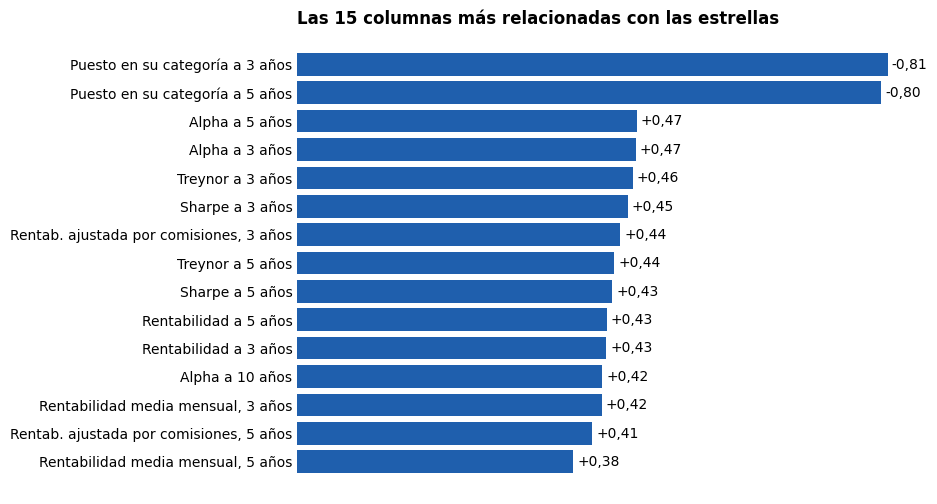

Columnas numéricas que quedan: 171
Primera columna que no es del historial: patrimonio, con 0.30


In [ ]:
nombres = {
    "fund_return_category_rank_3years": "Puesto en su categoría a 3 años",
    "fund_return_category_rank_5years": "Puesto en su categoría a 5 años",
    "fund_alpha_3years": "Alpha a 3 años",
    "fund_alpha_5years": "Alpha a 5 años",
    "fund_alpha_10years": "Alpha a 10 años",
    "fund_treynor_ratio_3years": "Treynor a 3 años",
    "fund_treynor_ratio_5years": "Treynor a 5 años",
    "fund_sharpe_ratio_3years": "Sharpe a 3 años",
    "fund_sharpe_ratio_5years": "Sharpe a 5 años",
    "load_adj_return_3years": "Rentab. ajustada por comisiones, 3 años",
    "load_adj_return_5years": "Rentab. ajustada por comisiones, 5 años",
    "fund_return_3years": "Rentabilidad a 3 años",
    "fund_return_5years": "Rentabilidad a 5 años",
    "fund_mean_annual_return_3years": "Rentabilidad media mensual, 3 años",
    "fund_mean_annual_return_5years": "Rentabilidad media mensual, 5 años",
    "fund_return_category_rank_1month": "Puesto en su categoría, último mes",
    "fund_return_2020": "Rentabilidad en 2020",
}

estrellas = fondos["morningstar_overall_rating"]
numericas = fondos.drop(columns=list(descartes)).select_dtypes("number").drop(columns="morningstar_overall_rating")
correlaciones = numericas.corrwith(estrellas, method="spearman")
top15 = correlaciones.loc[correlaciones.abs().sort_values(ascending=False).index[:15]][::-1]   # la más fuerte, arriba

fig, ax = plt.subplots(figsize=(8, 6))
barras = ax.barh([nombres.get(c, c) for c in top15.index], top15.abs(), color="#1F5FAD")
ax.bar_label(barras, labels=[f"{v:+.2f}".replace(".", ",") for v in top15.values], padding=3)
ax.set_title("Las 15 columnas más relacionadas con las estrellas", loc="left", fontweight="bold")
ax.set_xticks([])                          # sin eje: el valor ya va escrito en cada barra
ax.tick_params(axis="y", length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
plt.show()

print(f"Columnas numéricas que quedan: {len(numericas.columns)}")
print(f"Primera columna que no es del historial: patrimonio, con {correlaciones['total_net_assets']:.2f}")

Nos llevamos una sorpresa. Muy por encima de todo está el **puesto del fondo dentro de su categoría** (-0,81 a 3 años y -0,80 a 5). Sale negativo porque el puesto 1 es el mejor: cuanto más bajo el puesto, más estrellas. Tiene toda la lógica, porque es justo lo que hace Morningstar: comparar cada fondo con los de su categoría.

Detrás, a mucha distancia y todas entre 0,38 y 0,47, vienen distintas formas de medir lo bien que lo ha hecho el fondo: el alpha, el Sharpe, el Treynor y la rentabilidad, normal o ajustada por comisiones, a 3, 5 y 10 años. La primera columna que no es del historial es el patrimonio, con 0,30.

Esto cambia lo que pensábamos quitar. Íbamos a quedarnos solo con la rentabilidad y el Sharpe a 3 y 5 años, pero el puesto en la categoría, el alpha y la rentabilidad ajustada por comisiones (que es la que usa Morningstar) se quedan también.

Ahora sí, simplificamos. Muchas de estas columnas son casi copias unas de otras. Lo comprobamos con algunos pares:

In [ ]:
pares = [
    ("fund_prospectus_net_expense_ratio", "fund_annual_report_net_expense_ratio"),
    ("fund_stdev_3years", "fund_stdev_5years"),
    ("fund_beta_3years", "fund_beta_5years"),
    ("fund_sharpe_ratio_3years", "fund_treynor_ratio_3years"),
    ("fund_return_3years", "fund_mean_annual_return_3years"),
]
for a, b in pares:
    print(f"{a:38s} vs {b:38s} correlación = {fondos[a].corr(fondos[b]):.3f}")

fund_prospectus_net_expense_ratio      vs fund_annual_report_net_expense_ratio   correlación = 1.000
fund_stdev_3years                      vs fund_stdev_5years                      correlación = 0.993
fund_beta_3years                       vs fund_beta_5years                       correlación = 0.996
fund_sharpe_ratio_3years               vs fund_treynor_ratio_3years              correlación = 0.936
fund_return_3years                     vs fund_mean_annual_return_3years         correlación = 0.956


Hay pares que son literalmente la misma información: las dos comisiones (1,000), la volatilidad y la beta a 3 y 5 años (0,99). De esos nos quedamos con uno. El Treynor y la rentabilidad media mensual también se parecen mucho a otras que ya tenemos (el Sharpe y la rentabilidad, 0,94-0,96), así que fuera.

Con lo que nos queda, cada columna aporta una idea distinta:

* **Rentabilidad:** la del fondo y la media de su categoría a 3 y 5 años (para restarlas en el apartado 5), y la **ajustada por comisiones** a 3, 5 y 10 años, que es la que usa Morningstar. La rentabilidad normal a 10 años la quitamos porque falta en casi la mitad de los fondos; la ajustada falta mucho menos.
* **Puesto en su categoría** a 3 y 5 años: la columna estrella del gráfico anterior.
* **Riesgo:** la volatilidad a 3 años, el Sharpe (rentabilidad por unidad de riesgo) y el alpha (lo que el gestor gana de más respecto al mercado), a 3, 5 y 10 años.
* **Costes:** la comisión anual del folleto.
* **Métricas de las acciones:** solo las del fondo, no la media de su categoría (la categoría ya la tenemos).

Y dejamos fuera las rentabilidades de cada año y trimestre y los puestos del último mes o trimestre: Morningstar mira 3, 5 y 10 años, no el corto plazo.

In [ ]:
columnas_finales = [
    # Identificación, target y categorías
    "fund_symbol", "morningstar_overall_rating",
    "fund_category", "investment_type", "size_type", "inception_date",
    # Tamaño y forma de gestionar
    "total_net_assets", "annual_holdings_turnover", "top10_holdings_total_assets",
    # Costes
    "fund_prospectus_net_expense_ratio",
    # Composición de la cartera
    "asset_stocks", "asset_bonds", "asset_cash", "asset_others", "asset_preferred", "asset_convertible",
    # Sectores
    "fund_sector_basic_materials", "fund_sector_communication_services", "fund_sector_consumer_cyclical",
    "fund_sector_consumer_defensive", "fund_sector_energy", "fund_sector_financial_services",
    "fund_sector_healthcare", "fund_sector_industrials", "fund_sector_real_estate",
    "fund_sector_technology", "fund_sector_utilities",
    # Métricas de las acciones de la cartera
    "fund_price_earning_ratio", "fund_price_book_ratio", "fund_price_sales_ratio",
    "fund_price_cashflow_ratio", "fund_median_market_cap", "fund_year3_earnings_growth",
    # Historial: rentabilidad
    "fund_return_3years", "fund_return_5years", "category_return_3years", "category_return_5years",
    "load_adj_return_3years", "load_adj_return_5years", "load_adj_return_10years",
    "fund_return_category_rank_3years", "fund_return_category_rank_5years",
    # Historial: riesgo
    "fund_stdev_3years", "fund_sharpe_ratio_3years", "fund_sharpe_ratio_5years", "fund_sharpe_ratio_10years",
    "fund_alpha_3years", "fund_alpha_5years", "fund_alpha_10years",
]

# Por seguridad: ninguna columna elegida puede haber caído en las reglas anteriores
assert not set(columnas_finales) & set(descartes)

descartar([c for c in fondos.columns if c not in columnas_finales], "Redundante o demasiado detalle")
fondos = fondos.drop(columns=list(descartes))

print(f"Columnas eliminadas: {len(descartes)} · Columnas que quedan: {fondos.shape[1]}")
pd.Series(descartes).value_counts().to_frame("columnas eliminadas")

Columnas eliminadas: 249 · Columnas que quedan: 49


,columnas eliminadas
Redundante o demasiado detalle,128
Más del 50 % de nulos,70
ESG,19
Precio de mercado,11
Texto o identificación,10
Valor constante,7
Fuga: piezas de las estrellas,2
Bonos (no aplica),2


De casi 300 columnas pasamos a **49**, y cada eliminación tiene su motivo apuntado. Si en algún momento queremos recuperar alguna, basta con mirar `descartes`.

### Paso 3: diccionario de las columnas que usamos

Antes de leerlo, un detalle de unidades: los porcentajes vienen en **tanto por uno**. `asset_stocks = 0.96` es un 96 % en acciones y `fund_prospectus_net_expense_ratio = 0.0122` es una comisión del 1,22 % al año. La volatilidad (`fund_stdev_3years`) es la excepción: viene ya en %.

**Target**

| Columna | Significado |
|---|---|
| `morningstar_overall_rating` | Estrellas de Morningstar, de 1 a 5. Comparan la rentabilidad del fondo, descontando comisiones y penalizando el riesgo, con la de los fondos de su categoría |

**Identificación y categorías**

| Columna | Significado |
|---|---|
| `fund_symbol` | Símbolo del fondo (*ticker*). Solo para identificarlo, no entra en el modelo |
| `fund_category` | Categoría de Morningstar (Large Blend, Technology, Small Value…): el grupo con el que se compara al fondo |
| `investment_type` | Estilo: Value (empresas baratas), Growth (empresas que crecen) o Blend (mezcla) |
| `size_type` | Tamaño de las empresas en las que invierte: Large, Medium o Small |
| `inception_date` | Fecha de creación. La convertiremos en antigüedad del fondo |

**Tamaño, gestión y costes**

| Columna | Significado |
|---|---|
| `total_net_assets` | Patrimonio del fondo, en dólares |
| `annual_holdings_turnover` | Rotación: qué parte de la cartera cambia en un año (0.74 = 74 %). Mucha rotación suele indicar gestión activa |
| `top10_holdings_total_assets` | Peso de las 10 mayores posiciones. Mide lo concentrada que está la cartera |
| `fund_prospectus_net_expense_ratio` | Comisión anual total (TER). Lo que cobra el fondo cada año |

**Composición de la cartera**

| Columna | Significado |
|---|---|
| `asset_stocks`, `asset_bonds`, `asset_cash` | Peso en acciones, bonos y liquidez |
| `asset_preferred`, `asset_convertible`, `asset_others` | Acciones preferentes, bonos convertibles y otros activos |
| `fund_sector_*` (11 columnas) | Peso de cada sector: tecnología, salud, financiero, energía, inmobiliario, consumo, industria… |

**Cómo son las empresas de la cartera**

| Columna | Significado |
|---|---|
| `fund_price_earning_ratio` | PER medio: cuántas veces sus beneficios anuales cuestan las empresas. Alto = empresas "caras" o de crecimiento |
| `fund_price_book_ratio`, `fund_price_sales_ratio`, `fund_price_cashflow_ratio` | Precio respecto al valor contable, a las ventas y al flujo de caja |
| `fund_median_market_cap` | Tamaño mediano de las empresas, en millones de dólares |
| `fund_year3_earnings_growth` | Crecimiento de beneficios de las empresas en los últimos 3 años (%) |

**Historial del fondo** (solo para el modelo "ficha completa")

| Columna | Significado |
|---|---|
| `fund_return_3years`, `fund_return_5years` | Rentabilidad anualizada del fondo a 3 y 5 años |
| `category_return_3years`, `category_return_5years` | Rentabilidad media de su categoría en los mismos plazos, para comparar |
| `load_adj_return_3years`, `_5years`, `_10years` | Rentabilidad anualizada descontando las comisiones de entrada y salida. Es la que usa Morningstar |
| `fund_return_category_rank_3years`, `_5years` | Puesto del fondo dentro de su categoría por rentabilidad, de 1 (el mejor) a 100 (el peor) |
| `fund_stdev_3years` | Volatilidad a 3 años (%): cuánto sube y baja |
| `fund_sharpe_ratio_3years`, `_5years`, `_10years` | Rentabilidad por unidad de riesgo. Más alto = mejor |
| `fund_alpha_3years`, `_5years`, `_10years` | Lo que el fondo gana de más (o de menos) respecto a lo que le tocaría por el riesgo de mercado que asume. Positivo = el gestor aporta |

In [ ]:
fondos.head()

,fund_symbol,fund_category,total_net_assets,morningstar_overall_rating,inception_date,annual_holdings_turnover,investment_type,size_type,fund_prospectus_net_expense_ratio,asset_cash,asset_stocks,asset_bonds,asset_others,asset_preferred,asset_convertible,fund_sector_basic_materials,fund_sector_communication_services,fund_sector_consumer_cyclical,fund_sector_consumer_defensive,fund_sector_energy,fund_sector_financial_services,fund_sector_healthcare,fund_sector_industrials,fund_sector_real_estate,fund_sector_technology,fund_sector_utilities,fund_price_book_ratio,fund_price_cashflow_ratio,fund_price_earning_ratio,fund_price_sales_ratio,fund_median_market_cap,fund_year3_earnings_growth,top10_holdings_total_assets,fund_return_3years,category_return_3years,fund_return_5years,category_return_5years,fund_alpha_3years,fund_stdev_3years,fund_sharpe_ratio_3years,fund_alpha_5years,fund_sharpe_ratio_5years,fund_alpha_10years,fund_sharpe_ratio_10years,fund_return_category_rank_3years,fund_return_category_rank_5years,load_adj_return_3years,load_adj_return_5years,load_adj_return_10years
1,AAAEX,Health,1.953489e+08,3.0,2020-07-13,0.91,Blend,Large,0.0109,0.0309,0.9691,0.0,0.0000,0.0,0.0,0.0368,0.0000,0.0034,0.0000,0.0000,0.0000,0.9598,0.0000,0.0000,0.0000,0.0000,4.68,14.38,26.87,2.13,56096.51,11.95,0.4285,NaN,0.1491,NaN,0.1429,6.59,15.82,1.05,3.18,0.93,6.14,0.96,24.0,62.0,0.1795,0.1448,0.1401
3,AAAGX,Large Growth,2.078607e+09,4.0,1999-10-29,0.44,Growth,Large,0.0108,0.0182,0.9818,0.0,0.0000,0.0,0.0,0.0000,0.1617,0.1957,0.0046,0.0000,0.1458,0.1326,0.0346,0.0000,0.3250,0.0000,10.20,26.30,37.45,5.74,337976.70,32.36,0.5565,0.31791,0.2090,0.19264,0.2041,4.92,20.21,1.14,5.01,1.30,0.91,1.03,26.0,26.0,0.2287,0.2269,0.1624
10,AAANX,Tactical Allocation,7.045766e+08,4.0,2012-01-31,2.08,Blend,Large,0.0151,0.0084,0.9915,0.0,0.0001,0.0,0.0,0.0372,0.0850,0.1104,0.0756,0.0371,0.1609,0.1117,0.1089,0.0291,0.1825,0.0616,3.07,14.03,22.53,2.11,65770.67,11.80,0.8584,0.16541,0.0830,0.11116,0.0858,-5.08,19.32,0.58,-2.97,0.74,NaN,NaN,17.0,12.0,0.1113,0.1206,NaN
41,AACFX,China Region,1.710428e+08,3.0,2006-03-31,0.59,Blend,Large,0.0150,0.0726,0.9274,0.0,0.0000,0.0,0.0,0.0163,0.2906,0.3264,0.0965,0.0000,0.0505,0.1615,0.0024,0.0000,0.0441,0.0117,2.75,12.35,22.86,1.78,31408.78,24.37,0.5062,0.02560,0.1071,0.07410,0.1535,3.17,16.82,0.53,5.40,0.82,2.21,0.40,74.0,65.0,0.0704,0.1175,0.0583
44,AACIX,Mid-Cap Value,2.172665e+08,2.0,2005-11-30,0.35,Value,Medium,0.0092,0.0325,0.9675,0.0,0.0000,0.0,0.0,0.0672,0.0179,0.1538,0.0361,0.0666,0.2515,0.0579,0.1999,0.0572,0.0309,0.0609,1.97,9.78,17.65,1.20,11973.58,2.07,0.1850,0.08570,0.1207,0.08630,0.1222,-13.18,29.48,0.43,-10.20,0.55,-6.99,0.60,70.0,51.0,0.0978,0.1186,0.1090


## 3. Exploración y visualización de los datos

Ya tenemos la tabla limpia: 12.308 fondos de acciones y 49 columnas. Para no hacer gráficos por hacer, vamos a ir
respondiendo preguntas concretas (las del índice, de la 3.1 a la 3.7).

En casi todos los gráficos miramos lo mismo: **qué % de fondos tiene 4 o 5 estrellas**. A esos los llamaremos
"fondos buenos". Así es fácil comparar unos gráficos con otros.

Sobre el estilo: un solo color para los datos y un azul más fuerte solo cuando queremos destacar algo. Y en los gráficos de
barras quitamos los ejes: el valor ya va escrito encima de cada barra.

In [ ]:
import matplotlib.ticker as mtick

AZUL = "#1F5FAD"   # color principal y de énfasis
GRIS = "#B8BEC6"   # color neutro para lo que no queremos destacar

plt.rcParams.update({
    "axes.spines.top": False,        # quitamos los bordes de arriba y de la derecha
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",    # título alineado a la izquierda, como un titular
    "axes.edgecolor": "#888888",
    "axes.labelcolor": "#444444",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
})

def sin_ejes(ax):
    # para los gráficos de barras: el valor va escrito encima, así que los ejes sobran
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.set_yticks([])
    ax.set_ylabel("")
    ax.tick_params(axis="x", length=0)

def miles(n):
    # 11431 -> "11.431"
    return f"{n:,.0f}".replace(",", ".")

con_rating = fondos.dropna(subset=["morningstar_overall_rating"]).copy()
con_rating["estrellas"] = con_rating["morningstar_overall_rating"].astype(int)
con_rating["fondo_bueno"] = con_rating["estrellas"] >= 4   # True si tiene 4 o 5 estrellas
pct_buenos_total = con_rating["fondo_bueno"].mean() * 100

print(f"Fondos con estrellas: {miles(len(con_rating))} · sin estrellas: {miles(fondos['morningstar_overall_rating'].isna().sum())}")
print(f"Fondos buenos (4 o 5 estrellas): {pct_buenos_total:.1f} %")

Fondos con estrellas: 11.431 · sin estrellas: 877
Fondos buenos (4 o 5 estrellas): 35.8 %


### 3.1 ¿Cuántos fondos hay de cada número de estrellas?

Morningstar reparte las estrellas dentro de cada categoría con una "campana": el 10 % mejor se lleva 5 estrellas, el
22,5 % siguiente 4, el 35 % del medio 3, el 22,5 % siguiente 2 y el 10 % peor, 1. Vamos a ver cómo sale en nuestros datos.

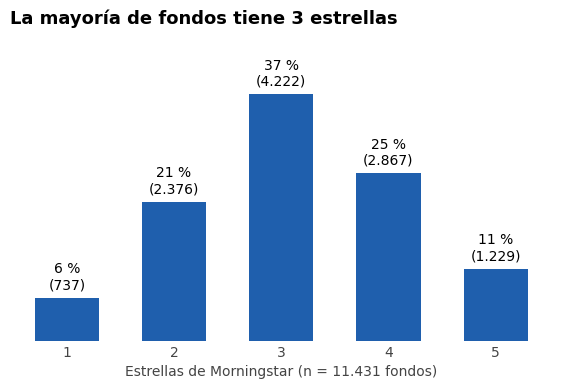

In [ ]:
conteo = con_rating["estrellas"].value_counts().sort_index()
porcentaje = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(conteo.index, porcentaje, color=AZUL, width=0.6)
ax.bar_label(barras, labels=[f"{p:.0f} %\n({miles(n)})" for p, n in zip(porcentaje, conteo)], padding=4)
ax.set_title("La mayoría de fondos tiene 3 estrellas")
ax.set_xlabel(f"Estrellas de Morningstar (n = {miles(conteo.sum())} fondos)")
ax.set_xticks([1, 2, 3, 4, 5])
sin_ejes(ax)
ax.set_ylim(0, porcentaje.max() * 1.25)
plt.show()

Un 37 % de los fondos tiene 3 estrellas y los extremos son los menos frecuentes: un 6 % tiene 1 estrella y un 11 % tiene 5. Se parece a la campana de Morningstar, aunque no del todo: hay menos fondos de 1 estrella de lo esperado (un 6 % frente al 10 %). Seguramente es porque el dataset no tiene todos los fondos de cada categoría y además nosotros solo miramos los de acciones.

Dos cosas que nos llevamos para el modelo:

- Las clases están **desbalanceadas**. Un modelo que diga siempre "3 estrellas" ya acierta un 37 %, así que esa es la nota mínima a superar.
- Fallar por una estrella (decir 4 cuando es 5) no es lo mismo que fallar por cuatro (decir 1 cuando es 5). Lo tendremos en cuenta al medir.

### 3.2 ¿Por qué hay fondos sin estrellas?

Hay 877 fondos sin estrellas. Nuestra sospecha es que son **fondos nuevos**: Morningstar no da estrellas hasta que un
fondo tiene 3 años de historia, y los datos son de finales de 2021. Lo comprobamos mirando, para cada año de creación,
qué % de fondos no tiene estrellas.

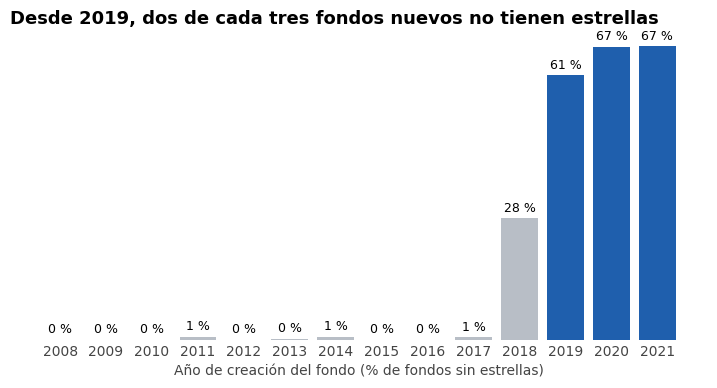

Año de creación (mediana):
morningstar_overall_rating
Con estrellas    2009.0
Sin estrellas    2019.0
Name: inception_date, dtype: float64


In [ ]:
anio_creacion = pd.to_datetime(fondos["inception_date"], errors="coerce").dt.year
sin_estrellas = fondos["morningstar_overall_rating"].isna()

pct_sin = sin_estrellas.groupby(anio_creacion).mean().loc[2008:2021] * 100   # % sin estrellas por año

fig, ax = plt.subplots(figsize=(9, 4))
colores = [AZUL if anio >= 2019 else GRIS for anio in pct_sin.index]       # destacamos los últimos 3 años
barras = ax.bar(pct_sin.index, pct_sin.values, color=colores)
ax.bar_label(barras, labels=[f"{v:.0f} %" for v in pct_sin.values], padding=3, fontsize=9)
ax.set_title("Desde 2019, dos de cada tres fondos nuevos no tienen estrellas")
ax.set_xlabel("Año de creación del fondo (% de fondos sin estrellas)")
ax.set_xticks(pct_sin.index)
sin_ejes(ax)
plt.show()

print("Año de creación (mediana):")
print(anio_creacion.groupby(sin_estrellas.map({True: "Sin estrellas", False: "Con estrellas"})).median())

Hasta 2017 prácticamente todos los fondos tienen estrellas. En 2018 ya le faltan a un 28 % (algunos no llegaban a los 3 años en diciembre de 2021) y desde 2019, a dos de cada tres. La mitad de los fondos con estrellas se creó antes de 2009; la mitad de los que no tienen, después de 2019. O sea: **no tienen estrellas porque son nuevos**, y por eso mismo tampoco tienen rentabilidad a 3 y 5 años.

¿Y el tercio de fondos de 2019-2021 que sí tiene estrellas? Creemos que son clases nuevas de fondos que ya existían, a las que Morningstar les aplica el historial de la clase original. No lo hemos comprobado, así que lo dejamos como hipótesis.

Lo importante: para puntuar fondos nuevos solo nos va a servir el modelo "solo ficha", porque el historial no existe.

### 3.3 ¿Cómo son los fondos?

Miramos la distribución de seis variables que resumen las ideas principales: tamaño, coste, gestión, rentabilidad y
riesgo. La línea azul es la mediana. El patrimonio va en escala logarítmica porque hay fondos de menos de un millón y
otros de cientos de miles de millones. En el resto quitamos el 1 % más extremo, solo para que se vea bien la forma.

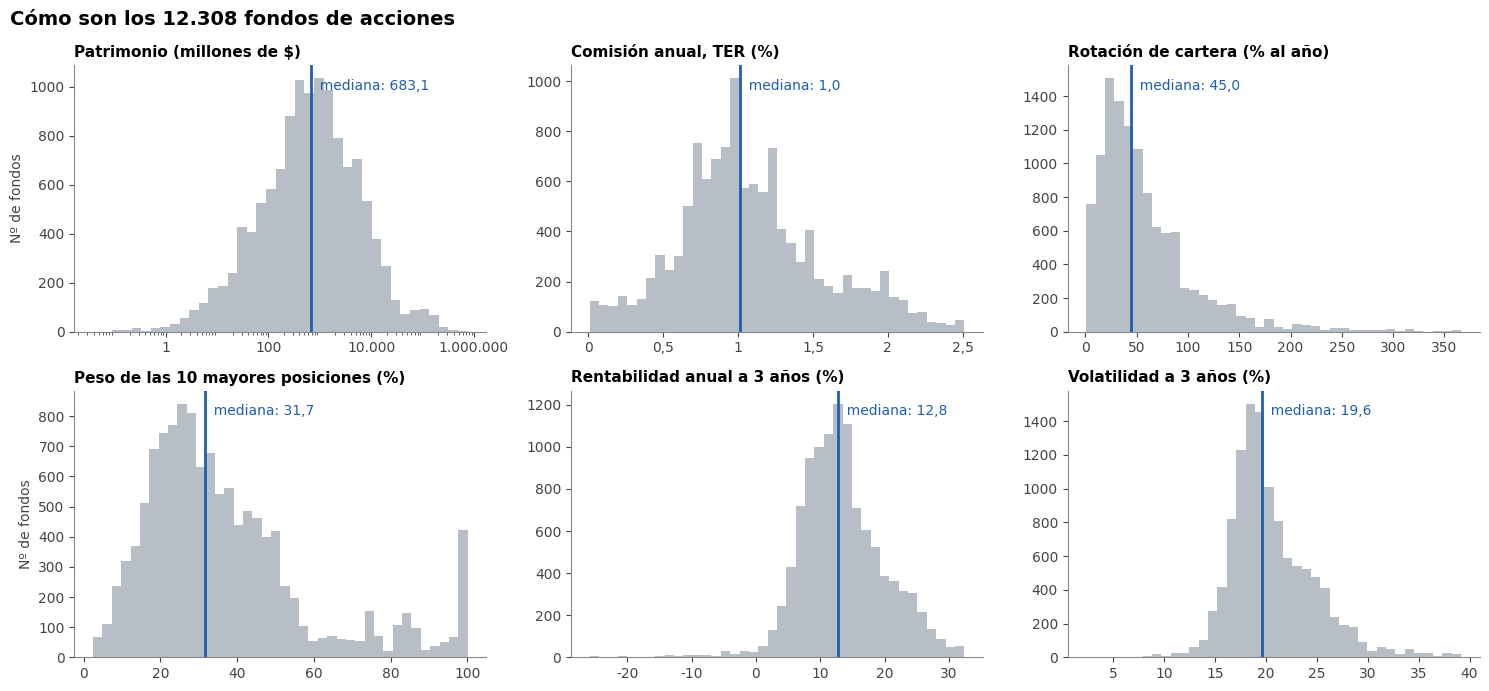

In [ ]:
variables = {
    # columna: (título, conversión a unidades legibles, ¿escala log?)
    "total_net_assets": ("Patrimonio (millones de $)", lambda s: s / 1e6, True),
    "fund_prospectus_net_expense_ratio": ("Comisión anual, TER (%)", lambda s: s * 100, False),
    "annual_holdings_turnover": ("Rotación de cartera (% al año)", lambda s: s * 100, False),
    "top10_holdings_total_assets": ("Peso de las 10 mayores posiciones (%)", lambda s: s * 100, False),
    "fund_return_3years": ("Rentabilidad anual a 3 años (%)", lambda s: s * 100, False),
    "fund_stdev_3years": ("Volatilidad a 3 años (%)", lambda s: s, False),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (columna, (titulo, convertir, log)) in zip(axes.flat, variables.items()):
    datos = convertir(fondos[columna].dropna())
    if log:
        datos = datos[datos > 0]
        bins = np.logspace(np.log10(datos.min()), np.log10(datos.max()), 40)
        ax.set_xscale("log")
        ax.set_xticks([1, 100, 10_000, 1_000_000])
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: miles(x)))
    else:
        datos = datos[datos <= datos.quantile(0.99)]
        bins = 40
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:g}".replace(".", ",")))  # 0,5 en vez de 0.5
    mediana = datos.median()
    ax.hist(datos, bins=bins, color=GRIS)
    ax.axvline(mediana, color=AZUL, linewidth=2)
    ax.text(mediana, ax.get_ylim()[1] * 0.95, f"  mediana: {mediana:,.1f}".replace(",", "X").replace(".", ",").replace("X", "."),
            color=AZUL, va="top")
    ax.set_title(titulo, fontsize=11)
axes[0, 0].set_ylabel("Nº de fondos")
axes[1, 0].set_ylabel("Nº de fondos")
fig.suptitle("Cómo son los 12.308 fondos de acciones", fontsize=14, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

Lo que vemos:

- **Patrimonio:** muy desigual. El fondo típico tiene unos 680 millones de dólares, pero hay desde menos de un millón hasta los cientos de miles de millones de los grandes indexados. En el modelo usaremos su logaritmo.
- **Comisión:** la mayoría cobra entre un 0,5 % y un 1,5 % al año, con mediana del 1 %. Los indexados baratos están pegados al cero.
- **Rotación:** la mitad cambia menos del 45 % de la cartera al año, pero hay fondos que la cambian entera varias veces.
- **Peso de las 10 mayores posiciones:** el pico en el 100 % nos llamó la atención. Son sobre todo fondos de jubilación por fecha (*Target-Date*), que son "fondos de fondos": invierten en menos de 10 fondos, así que esas 10 posiciones son toda la cartera.
- **Rentabilidad y volatilidad a 3 años:** mediana de un 12,8 % al año con una volatilidad del 19,6 %. Son cifras altas porque los datos son de finales de 2021, después de unos años muy buenos en bolsa.

Cada variable va en una escala muy distinta (millones de dólares frente a porcentajes pequeños), así que habrá que escalar para los modelos que lo necesiten.

### 3.4 ¿Influye el estilo del fondo?

Los fondos de acciones se suelen clasificar por **estilo** (`investment_type`):

- **Value:** empresas "baratas", que cotizan a pocas veces sus beneficios (bancos, energía, industria...).
- **Growth:** empresas que crecen rápido y cotizan caras (tecnología sobre todo).
- **Blend:** una mezcla de las dos.

Como Morningstar reparte las estrellas dentro de cada categoría, en teoría el % de fondos buenos debería ser parecido
en los tres estilos. Lo comprobamos.

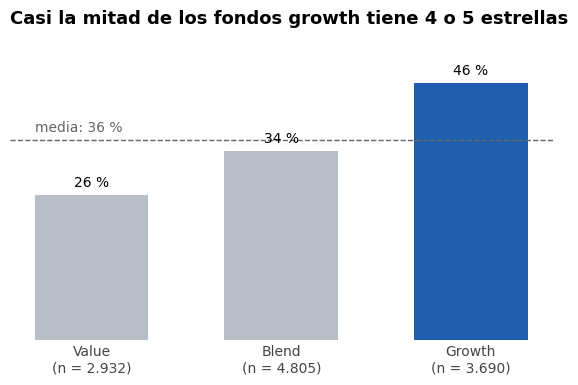

investment_type,Value,Blend,Growth
size_type,,,
Large,26.0,33.0,46.0
Medium,29.0,35.0,46.0
Small,25.0,39.0,45.0


In [ ]:
orden_estilo = ["Value", "Blend", "Growth"]
pct_estilo = con_rating.groupby("investment_type")["fondo_bueno"].mean().reindex(orden_estilo) * 100
n_estilo = con_rating["investment_type"].value_counts().reindex(orden_estilo)

fig, ax = plt.subplots(figsize=(7, 4))
colores = [AZUL if estilo == "Growth" else GRIS for estilo in orden_estilo]
barras = ax.bar([f"{e}\n(n = {miles(n)})" for e, n in zip(orden_estilo, n_estilo)], pct_estilo, color=colores, width=0.6)
ax.bar_label(barras, labels=[f"{v:.0f} %" for v in pct_estilo], padding=4)
ax.axhline(pct_buenos_total, color="#666666", linestyle="--", linewidth=1)
ax.text(-0.3, pct_buenos_total + 1, f"media: {pct_buenos_total:.0f} %", va="bottom", color="#666666")
ax.set_title("Casi la mitad de los fondos growth tiene 4 o 5 estrellas")
sin_ejes(ax)
ax.set_ylim(0, pct_estilo.max() * 1.2)
plt.show()

# ¿Pasa lo mismo sea cual sea el tamaño de las empresas?
tabla = con_rating.pivot_table(index="size_type", columns="investment_type", values="fondo_bueno", aggfunc="mean") * 100
tabla.loc[["Large", "Medium", "Small"], orden_estilo].round(0)

Casi la mitad de los fondos *growth* (46 %) tiene 4 o 5 estrellas, frente a solo un 26 % de los *value*. Y la tabla muestra que pasa lo mismo con empresas grandes, medianas y pequeñas.

En teoría esto no debería pasar, porque las estrellas se reparten dentro de cada categoría. No sabemos seguro por qué ocurre. Nuestra hipótesis es que el dataset no tiene todos los fondos con los que Morningstar compara, y que justo antes de 2021 las empresas *growth* (tecnológicas sobre todo) subieron muchísimo. Sea por lo que sea, el estilo da información, así que `investment_type` se queda en el modelo.

### 3.5 ¿Los fondos baratos y grandes tienen más estrellas?

Aquí está la base del modelo "solo ficha". Las estrellas se calculan con la rentabilidad **después de comisiones**, así
que un fondo caro parte con desventaja. Y los fondos a los que les va bien atraen dinero, así que es de esperar que los
grandes tengan más estrellas.

Agrupamos los fondos en tramos de comisión y de patrimonio, y miramos el % de fondos buenos en cada tramo. Los dos
gráficos comparten el eje vertical para poder compararlos.

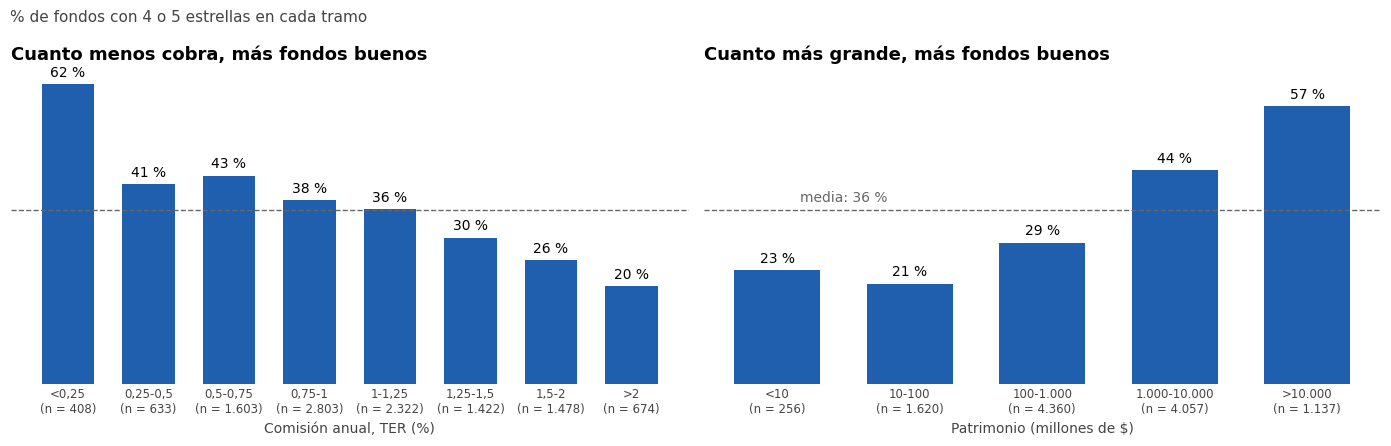

In [ ]:
tramos_ter = pd.cut(con_rating["fund_prospectus_net_expense_ratio"] * 100,
                    bins=[0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 2, 100],
                    labels=["<0,25", "0,25-0,5", "0,5-0,75", "0,75-1", "1-1,25", "1,25-1,5", "1,5-2", ">2"])
tramos_patrimonio = pd.cut(con_rating["total_net_assets"] / 1e6,
                           bins=[0, 10, 100, 1_000, 10_000, np.inf],
                           labels=["<10", "10-100", "100-1.000", "1.000-10.000", ">10.000"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, tramos, titulo, etiqueta_x in [
    (axes[0], tramos_ter, "Cuanto menos cobra, más fondos buenos", "Comisión anual, TER (%)"),
    (axes[1], tramos_patrimonio, "Cuanto más grande, más fondos buenos", "Patrimonio (millones de $)"),
]:
    pct = con_rating.groupby(tramos, observed=True)["fondo_bueno"].mean() * 100
    n = tramos.value_counts().reindex(pct.index)
    barras = ax.bar([f"{t}\n(n = {miles(k)})" for t, k in zip(pct.index, n)], pct, color=AZUL, width=0.65)
    ax.bar_label(barras, labels=[f"{v:.0f} %" for v in pct], padding=3)
    ax.axhline(pct_buenos_total, color="#666666", linestyle="--", linewidth=1)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x)
    ax.tick_params(axis="x", labelsize=8.5)
    sin_ejes(ax)
axes[1].text(0.5, pct_buenos_total + 1, f"media: {pct_buenos_total:.0f} %", ha="center", va="bottom", color="#666666")
fig.suptitle("% de fondos con 4 o 5 estrellas en cada tramo", fontsize=11, color="#444444", x=0.01, ha="left")
plt.tight_layout()
plt.show()

Las dos relaciones se cumplen, y muy claras:

- **Comisión:** entre los fondos que cobran menos de un 0,25 % al año, un 62 % tiene 4 o 5 estrellas. Entre los que cobran más de un 2 %, solo un 20 %. Tiene lógica: Morningstar mide la rentabilidad después de comisiones.
- **Patrimonio:** en los fondos de menos de 100 millones solo un 21-23 % son buenos; en los de más de 10.000 millones, un 57 %. Aquí la flecha seguramente va al revés: no es que ser grande dé estrellas, sino que los fondos a los que les va bien atraen el dinero.

Aun así, ningún tramo pasa del 62 %: hay fondos baratos con pocas estrellas y fondos caros con muchas. Con solo la comisión y el tamaño no basta.

### 3.6 ¿Basta con haber ganado mucho?

Este es el gráfico que más nos interesa. Partimos los fondos en 5 grupos del mismo tamaño (quintiles) de dos formas:

- **Izquierda:** según lo que ha ganado el fondo en los últimos 3 años.
- **Derecha:** según lo que ha ganado **frente a su categoría** (lo que ganó el fondo menos lo que ganó de media su
  categoría).

Si las estrellas se dan por ganarle a los fondos parecidos, el gráfico de la derecha debería subir mucho más.

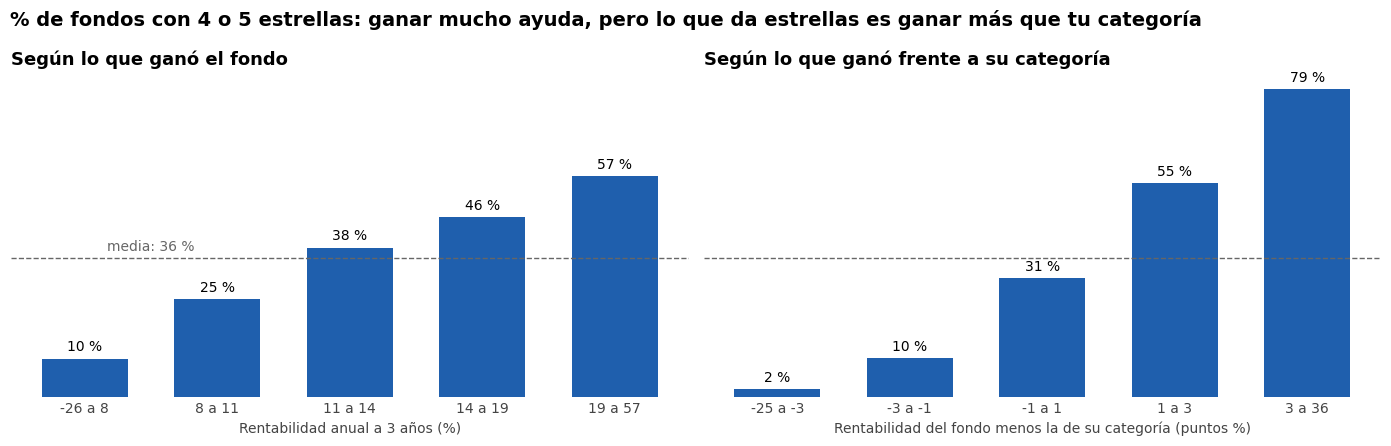

In [ ]:
datos = con_rating.dropna(subset=["fund_return_3years", "category_return_3years"]).copy()
datos["rentabilidad_3a"] = datos["fund_return_3years"] * 100
datos["diferencia_3a"] = (datos["fund_return_3years"] - datos["category_return_3years"]) * 100   # en puntos

def etiquetas_tramos(tramos):
    # convierte los intervalos de qcut en textos como "8 a 11"
    return [f"{t.left:.0f} a {t.right:.0f}" for t in tramos.cat.categories]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, columna, titulo, etiqueta_x in [
    (axes[0], "rentabilidad_3a", "Según lo que ganó el fondo", "Rentabilidad anual a 3 años (%)"),
    (axes[1], "diferencia_3a", "Según lo que ganó frente a su categoría", "Rentabilidad del fondo menos la de su categoría (puntos %)"),
]:
    tramos = pd.qcut(datos[columna], 5)
    pct = datos.groupby(tramos, observed=True)["fondo_bueno"].mean() * 100
    barras = ax.bar(etiquetas_tramos(tramos), pct, color=AZUL, width=0.65)
    ax.bar_label(barras, labels=[f"{v:.0f} %" for v in pct], padding=3)
    ax.axhline(pct_buenos_total, color="#666666", linestyle="--", linewidth=1)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x)
    sin_ejes(ax)
axes[0].text(0.5, pct_buenos_total + 1, f"media: {pct_buenos_total:.0f} %", ha="center", va="bottom", color="#666666")
fig.suptitle("% de fondos con 4 o 5 estrellas: ganar mucho ayuda, pero lo que da estrellas es ganar más que tu categoría",
             fontsize=14, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

La diferencia se ve a simple vista. Si ordenamos los fondos por lo que han ganado, el % de fondos buenos sube del 10 % al 57 %. Pero si los ordenamos por lo que han ganado **frente a su categoría**, va del 2 % al 79 %: casi ningún fondo que pierde contra su categoría tiene 4 o 5 estrellas, y casi todos los que le ganan por más de 3 puntos sí las tienen.

Es decir: un fondo que gana un 20 % al año puede tener pocas estrellas si los fondos parecidos ganaron un 25 %.

Lo comprobamos con un número: la correlación de Spearman (la del apartado 2) de la rentabilidad "a secas" y de la
diferencia frente a la categoría.

In [ ]:
diferencia_3a = con_rating["fund_return_3years"] - con_rating["category_return_3years"]
print(f"Rentabilidad a 3 años                 vs estrellas: "
      f"{con_rating['fund_return_3years'].corr(con_rating['estrellas'], method='spearman'):.2f}")
print(f"Rentabilidad a 3 años - la categoría  vs estrellas: "
      f"{diferencia_3a.corr(con_rating['estrellas'], method='spearman'):.2f}")

Rentabilidad a 3 años                 vs estrellas: 0.43
Rentabilidad a 3 años - la categoría  vs estrellas: 0.70


La rentabilidad "a secas" tiene una correlación de 0,43 con las estrellas, y la diferencia frente a la categoría llega a **0,70**. Es la misma idea que el puesto en la categoría del apartado 2 (-0,81): lo que cuenta no es cuánto gana el fondo, sino cuánto gana **comparado con los suyos**. Esta diferencia no viene en el dataset, así que la crearemos nosotros en el apartado 5, a 3 y 5 años, para el modelo "ficha completa".

### 3.7 La trampa: el mismo fondo aparece varias veces

Un mismo fondo se suele vender en varias **clases de participación**: misma cartera y mismo gestor, pero distinta
comisión según quién lo compre (particular, institucional, plan de pensiones...). En el dataset cada clase es una fila.
Lo vemos con el famoso fondo indexado al S&P 500 de Vanguard.

In [ ]:
vanguard_500 = ["VFIAX", "VFINX", "VFFSX"]
fondos.loc[fondos["fund_symbol"].isin(vanguard_500),
           ["fund_symbol", "inception_date", "fund_category", "total_net_assets", "asset_stocks", "fund_sector_technology",
            "fund_prospectus_net_expense_ratio", "fund_return_3years", "morningstar_overall_rating"]]

,fund_symbol,inception_date,fund_category,total_net_assets,asset_stocks,fund_sector_technology,fund_prospectus_net_expense_ratio,fund_return_3years,morningstar_overall_rating
22574,VFFSX,2016-06-24,Large Blend,7.534100e+11,0.9996,0.2424,0.0001,0.1835,4.0
22578,VFIAX,2000-11-13,Large Blend,7.534100e+11,0.9996,0.2424,0.0004,0.1832,5.0
22583,VFINX,1976-08-31,Large Blend,7.534100e+11,0.9996,0.2424,0.0014,0.1820,4.0


Son tres filas, pero es **un solo fondo**: misma categoría, mismo patrimonio (753.410 millones de dólares, el del fondo entero), misma composición y casi la misma rentabilidad. Lo único que cambia es la comisión (de un 0,01 % a un 0,14 %), y por eso tienen estrellas diferentes. Que VFFSX, la clase más barata, tenga 4 estrellas y no 5 seguramente se debe a que se creó en 2016 y Morningstar solo la puede valorar con un historial más corto.

¿Por qué es una trampa? Si al separar train y test VFIAX cae en train y VFINX en test, el modelo "se sabe la respuesta": ha visto la misma cartera y solo tiene que copiar. Las métricas saldrían mucho mejores de lo que serían con un fondo nuevo de verdad.

Para encontrar todas las clases de un mismo fondo no podemos usar el nombre (está descolocado, lo vimos en el apartado 2).
Usamos su "huella": si dos filas tienen exactamente la misma categoría, el mismo patrimonio, el mismo reparto de activos y
los mismos sectores, son la misma cartera. Guardamos ese número de cartera en una columna nueva, `cartera`, que **no**
será una variable del modelo; solo la usaremos para separar los datos.

In [ ]:
huella = [c for c in fondos.columns if c.startswith(("asset_", "fund_sector_"))] + ["fund_category", "total_net_assets"]
fondos["cartera"] = fondos.groupby(huella, dropna=False).ngroup()

clases_por_cartera = fondos["cartera"].value_counts()
print(f"Filas (clases de participación): {len(fondos):,}")
print(f"Carteras distintas:              {fondos['cartera'].nunique():,}")
print(f"Carteras con más de una clase:   {(clases_por_cartera > 1).sum():,}")

con_cartera = fondos.dropna(subset=["morningstar_overall_rating"])
varias = con_cartera.groupby("cartera").filter(lambda g: len(g) > 1)
distintas = (varias.groupby("cartera")["morningstar_overall_rating"].nunique() > 1).mean()
print(f"De las carteras con varias clases, con estrellas distintas entre clases: {distintas:.0%}")

Filas (clases de participación): 12,308
Carteras distintas:              3,780
Carteras con más de una clase:   2,650
De las carteras con varias clases, con estrellas distintas entre clases: 49%


Las 12.308 filas son en realidad **3.780 carteras**, y 2.650 de ellas tienen más de una clase. Además, en casi la mitad de esas carteras (49 %) las clases tienen estrellas distintas entre sí, que es justo lo que el modelo tendrá que distinguir usando la comisión.

Por eso, cuando separemos los datos (apartado 5) y hagamos validación cruzada (apartado 6), lo haremos **por cartera y no por fila**: todas las clases de un mismo fondo irán juntas a train o juntas a test. Para eso existe `StratifiedGroupKFold` de scikit-learn, que además mantiene el reparto de estrellas parecido en cada parte.

### Qué nos llevamos de la exploración

- **El target** está desbalanceado y centrado en 3 estrellas. La nota mínima a batir es un 37 % de acierto.
- **Los fondos sin estrellas son nuevos.** Para ellos solo sirve el modelo "solo ficha".
- **Para el modelo "solo ficha"** las pistas son la comisión, el tamaño, el estilo (*growth*/*value*) y los sectores. Ninguna es muy fuerte sola.
- **Para el modelo "ficha completa"** la clave es ganar **más que la categoría**: lo dice el puesto en la categoría
  (apartado 2) y lo confirma el 3.6. En el apartado 5 crearemos variables que midan justo eso.
- **Hay que separar por cartera**, no por fila: las 12.308 filas son solo 3.780 fondos distintos.

## 4. Exposición del objetivo

**Qué queremos predecir:** las estrellas de Morningstar de un fondo (`morningstar_overall_rating`), de 1 a 5, a partir
de su ficha. Es nuestro "Morningstar casero".

**Tipo de problema:** aprendizaje **supervisado** (tenemos la respuesta correcta de más de 11.000 fondos) y de
**clasificación multiclase** (5 clases).

Las estrellas tienen un orden (5 es mejor que 4), así que también se podría plantear como una regresión: predecir un
número como 3,4 y redondearlo. Nos quedamos con clasificación porque Morningstar da estrellas enteras y porque así podemos
usar los clasificadores que hemos visto en clase.

**Qué no usamos:** el rating de rentabilidad y el de riesgo de Morningstar, porque son las piezas con las que se
calculan las estrellas (lo explicamos en el apartado 2).

Separamos los fondos en dos grupos: los que tienen estrellas, que son los que usaremos para entrenar y evaluar, y los que
no, que guardamos para el final, para ponerles estrellas con nuestro modelo.

In [ ]:
fondos_con_estrellas = fondos[fondos["morningstar_overall_rating"].notna()].copy()
fondos_sin_estrellas = fondos[fondos["morningstar_overall_rating"].isna()].copy()

y = fondos_con_estrellas["morningstar_overall_rating"].astype(int)

print(f"Fondos con estrellas (entrenar y evaluar): {len(fondos_con_estrellas):,}")
print(f"Fondos sin estrellas (los puntuaremos al final): {len(fondos_sin_estrellas):,}")
print(f"Nota mínima: si decimos siempre {y.mode()[0]} estrellas, acertamos un {(y == y.mode()[0]).mean():.1%}")

Fondos con estrellas (entrenar y evaluar): 11,431
Fondos sin estrellas (los puntuaremos al final): 877
Nota mínima: si decimos siempre 3 estrellas, acertamos un 36.9%


Tenemos 11.431 fondos con la respuesta conocida, que son con los que aprenderá y se evaluará el modelo, y 877 sin estrellas que dejamos aparte. Un modelo que no piense nada y diga siempre "3 estrellas" ya acierta un 36,9 %. Cualquier modelo que hagamos tiene que superar claramente esa cifra para que valga la pena.

### Dos versiones del modelo

La pregunta con la que empezamos era: ¿cuánto se puede adivinar de las estrellas solo con cómo es el fondo, y cuánto
ayuda saber lo que ha ganado? Por eso entrenaremos dos versiones:

| | Modelo A: "solo ficha" | Modelo B: "ficha completa" |
|---|---|---|
| **Qué ve** | Categoría y estilo, tamaño, comisión, rotación, concentración, composición, sectores, cómo son las empresas que tiene y antigüedad del fondo | Todo lo del modelo A **más** el historial: rentabilidades a 3, 5 y 10 años, puesto en su categoría, volatilidad, Sharpe y alpha |
| **Para qué sirve** | Puntuar fondos nuevos, que todavía no tienen historial (los 877 sin estrellas) | Puntuar fondos que tienen historia pero que Morningstar no cubre (no todos los fondos del mundo están en Morningstar), imitándolo lo mejor posible |
| **Qué esperamos** | Algo por encima de la nota mínima, sin pasarse | Bastante mejor, sobre todo gracias a lo que gana frente a su categoría (apartados 2 y 3.6) |

La diferencia entre los dos nos dirá cuánto pesa el pasado en las estrellas.

### Cómo vamos a medir

Con cinco clases desbalanceadas, el accuracy solo se queda corto. Miraremos cuatro cosas:

- **Accuracy:** el % de fondos en los que acertamos las estrellas exactas. Es la que conocemos y la que hay que comparar
  con la nota mínima del 37 %.
- **Acierto a una estrella:** el % de fondos en los que nos equivocamos como mucho en una estrella. Decir 4 a un fondo de
  5 es un fallo pequeño; decir 1 es un fallo gordo. Esta métrica la calculamos nosotros, no viene en scikit-learn.
- **F1 macro:** para cada número de estrellas calcula el F1 (una nota que combina "de los que dije que eran de 5
  estrellas, cuántos lo eran" y "de los que eran de 5 estrellas, cuántos encontré") y hace la media dando el mismo peso
  a las cinco clases. Así, un modelo que se olvide de los fondos de 1 y 5 estrellas (los raros) saca mala nota aunque
  tenga buen accuracy.
- **Matriz de confusión:** para ver en qué se equivoca y si los fallos son "de una estrella" o más.

Para elegir modelos e hiperparámetros usaremos el **F1 macro**, porque castiga ignorar las clases pequeñas, y
comprobaremos las otras.

### Cómo vamos a separar los datos

Por lo que vimos en el apartado 3.7, separamos **por cartera** y no por fila: todas las clases de un mismo fondo van
juntas a train o juntas a test.

- **Test:** un 20 % de las carteras, apartado desde el principio. Solo lo usamos una vez, al final.
- **Train:** el 80 % restante. Ahí comparamos modelos y ajustamos hiperparámetros con validación cruzada de 5 partes,
  también separada por cartera (`StratifiedGroupKFold`).

## 5. Preparación de los datos

En este apartado dejamos los datos listos para entrenar, en cuatro pasos:

1. Crear unas pocas variables nuevas que nos sugirió la exploración.
2. Decidir qué variables ve cada modelo (A y B).
3. Separar train y test **por cartera**.
4. Montar el preprocesado (nulos, categorías y escalado) dentro de un `Pipeline`, para que se ajuste solo con train.

### 5.1 Variables nuevas

Creamos tres cosas a partir de columnas que ya tenemos:

- **Diferencia frente a la categoría** (a 3 y 5 años): lo que ganó el fondo menos lo que ganó su categoría. En el
  apartado 3.6 vimos que es lo que más se relaciona con las estrellas.
- **Logaritmo del patrimonio:** el patrimonio va de menos de un millón a cientos de miles de millones. Con el logaritmo
  (en base 10, sobre millones de dólares) un 3 es un fondo de 1.000 millones y un 5, uno de 100.000. Así los gigantes no
  aplastan al resto en los modelos que miden distancias, como KNN.
- **Antigüedad** del fondo en años, a partir de la fecha de creación. Como los datos son de finales de 2021, la
  calculamos a 31 de diciembre de 2021.

Lo metemos en una función para aplicarlo igual a los fondos con y sin estrellas. Cada fila se calcula solo con sus
propios datos, así que hacerlo antes de separar train y test no provoca ninguna fuga.

In [ ]:
def crear_variables(df):
    df = df.copy()
    df["diferencia_categoria_3a"] = df["fund_return_3years"] - df["category_return_3years"]
    df["diferencia_categoria_5a"] = df["fund_return_5years"] - df["category_return_5years"]
    df["log_patrimonio"] = np.log10(df["total_net_assets"] / 1e6)
    creacion = pd.to_datetime(df["inception_date"], errors="coerce")
    df["antiguedad_anios"] = (pd.Timestamp("2021-12-31") - creacion).dt.days / 365.25
    return df

fondos_con_estrellas = crear_variables(fondos_con_estrellas)
fondos_sin_estrellas = crear_variables(fondos_sin_estrellas)

nuevas = ["diferencia_categoria_3a", "diferencia_categoria_5a", "log_patrimonio", "antiguedad_anios"]
fondos_con_estrellas[nuevas].describe().round(3)

,diferencia_categoria_3a,diferencia_categoria_5a,log_patrimonio,antiguedad_anios
count,10449.000,8466.000,11430.000,11431.000
mean,0.002,-0.028,2.882,14.204
std,0.044,0.028,0.905,9.500
min,-0.249,-0.220,-0.765,0.504
25%,-0.022,-0.043,2.312,6.765
50%,-0.001,-0.028,2.897,12.597
75%,0.023,-0.014,3.484,19.863
max,0.361,0.115,5.877,97.462


Las variables tienen valores razonables:

- **Diferencia a 3 años:** está centrada en cero (la mediana es -0,1 puntos). Tiene sentido: la mitad de los fondos gana más que su categoría y la otra mitad, menos.
- **Diferencia a 5 años:** sale de media en -2,8 puntos, como si casi todos los fondos ganaran menos que su categoría. Eso es raro. Parece que en el dataset la rentabilidad de la categoría a 5 años está calculada de otra manera (quizá con otra fecha o con otros fondos). No lo hemos podido aclarar. Como el desplazamiento es parecido para todos, sigue sirviendo para ordenar los fondos de mejor a peor, que es lo que importa; lo comprobamos justo debajo.
- **Logaritmo del patrimonio:** va de -0,8 (menos de un millón) a 5,9 (unos 750.000 millones), con la mitad de los fondos entre 2,3 y 3,5 (de 200 a 3.000 millones).
- **Antigüedad:** la mediana es de 12,6 años, y hay algún fondo de casi 100.

Comprobamos también que las variables nuevas tienen relación con las estrellas (correlación de Spearman, como en el
apartado 3).

In [ ]:
fondos_con_estrellas[nuevas].corrwith(y, method="spearman").round(2).to_frame("Correlación con las estrellas")

,Correlación con las estrellas
diferencia_categoria_3a,0.70
diferencia_categoria_5a,0.69
log_patrimonio,0.30
antiguedad_anios,-0.05


Las dos diferencias frente a la categoría (0,70 y 0,69) son, después del puesto en la categoría (-0,81), lo más relacionado con las estrellas, muy por encima de la rentabilidad a secas (0,43). El patrimonio en logaritmo mantiene el 0,30 de antes: Spearman solo mira el orden, y el logaritmo no cambia el orden. Así que el logaritmo no se hace para Spearman, sino para los modelos que miden distancias. La antigüedad, en cambio, casi no tiene relación con las estrellas (-0,05): que un fondo sea viejo no lo hace mejor ni peor.

### 5.2 Qué variables ve cada modelo

Antes de hacer las listas, una comprobación. La idea del modelo A es puntuar fondos nuevos, así que miramos si en los
fondos con estrellas hay fondos tan jóvenes como los que queremos puntuar.

In [ ]:
for nombre, df in [("Con estrellas", fondos_con_estrellas), ("Sin estrellas", fondos_sin_estrellas)]:
    jovenes = (df["antiguedad_anios"] < 3).mean()
    print(f"{nombre}: antigüedad mediana {df['antiguedad_anios'].median():.1f} años · con menos de 3 años: {jovenes:.0%}")

Con estrellas: antigüedad mediana 12.6 años · con menos de 3 años: 3%
Sin estrellas: antigüedad mediana 2.0 años · con menos de 3 años: 82%


Aquí tomamos una decisión. Entre los fondos con estrellas, solo un 3 % tiene menos de 3 años, mientras que de los fondos sin estrellas lo es el 82 %. Si metiéramos la antigüedad en el modelo A, ante un fondo de 1 año estaría adivinando con un dato que casi no ha visto en el entrenamiento. Por eso **la antigüedad va solo en el modelo B**, junto al historial: en realidad es también un dato "del pasado" del fondo.

In [ ]:
categoricas = ["fund_category", "investment_type", "size_type"]

numericas_A = (
    ["log_patrimonio", "fund_prospectus_net_expense_ratio", "annual_holdings_turnover", "top10_holdings_total_assets"]
    + [c for c in fondos_con_estrellas.columns if c.startswith("asset_")]
    + [c for c in fondos_con_estrellas.columns if c.startswith("fund_sector_")]
    + ["fund_price_earning_ratio", "fund_price_book_ratio", "fund_price_sales_ratio",
       "fund_price_cashflow_ratio", "fund_median_market_cap", "fund_year3_earnings_growth"]
)

historial = [
    "fund_return_3years", "fund_return_5years", "category_return_3years", "category_return_5years",
    "diferencia_categoria_3a", "diferencia_categoria_5a",
    "load_adj_return_3years", "load_adj_return_5years", "load_adj_return_10years",
    "fund_return_category_rank_3years", "fund_return_category_rank_5years",
    "fund_stdev_3years", "fund_sharpe_ratio_3years", "fund_sharpe_ratio_5years", "fund_sharpe_ratio_10years",
    "fund_alpha_3years", "fund_alpha_5years", "fund_alpha_10years",
    "antiguedad_anios",
]
numericas_B = numericas_A + historial

print(f"Modelo A (solo ficha):     {len(numericas_A)} numéricas + {len(categoricas)} categóricas")
print(f"Modelo B (ficha completa): {len(numericas_B)} numéricas + {len(categoricas)} categóricas")

Modelo A (solo ficha):     27 numéricas + 3 categóricas
Modelo B (ficha completa): 46 numéricas + 3 categóricas


### 5.3 Separar train y test por cartera

Como explicamos en el apartado 4, todas las clases de un mismo fondo tienen que caer en el mismo lado. Usamos
`StratifiedGroupKFold`, que hace dos cosas a la vez:

- **Group:** no parte ningún grupo (aquí, ninguna `cartera`) entre dos trozos.
- **Stratified:** intenta que cada trozo tenga el mismo reparto de estrellas que el total, como el `stratify=y` de
  `train_test_split`.

Lo dividimos en 5 trozos y nos quedamos con uno como test: un 20 % de los datos, que no volveremos a tocar hasta el
final. Los otros 4 trozos son el train. Usamos el mismo objeto `cv_grupos` para la validación cruzada del apartado 6.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
X = fondos_con_estrellas[numericas_B + categoricas]  # el modelo A usará solo una parte de estas columnas
grupos = fondos_con_estrellas["cartera"]

indices_train, indices_test = next(cv_grupos.split(X, y, groups=grupos))
X_train, X_test = X.iloc[indices_train], X.iloc[indices_test]
y_train, y_test = y.iloc[indices_train], y.iloc[indices_test]
grupos_train = grupos.iloc[indices_train]

carteras_en_los_dos = set(grupos.iloc[indices_train]) & set(grupos.iloc[indices_test])
print(f"Train: {len(X_train):,} fondos ({grupos_train.nunique():,} carteras)")
print(f"Test:  {len(X_test):,} fondos ({grupos.iloc[indices_test].nunique():,} carteras)")
print(f"Carteras que aparecen en train y en test a la vez: {len(carteras_en_los_dos)}")

Train: 9,109 fondos (2,749 carteras)
Test:  2,322 fondos (685 carteras)
Carteras que aparecen en train y en test a la vez: 0


Comprobamos que train y test tienen el mismo reparto de estrellas. Como queremos ver valores exactos, una tabla es más clara que un gráfico.

In [ ]:
comparacion = pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index() * 100,
}).rename_axis("Estrellas")
comparacion.round(1)

,Train (%),Test (%)
Estrellas,,
1,6.4,6.7
2,19.9,24.2
3,36.8,37.6
4,25.8,22.4
5,11.1,9.2


Salen 9.144 fondos (2.749 carteras) para train y 2.287 fondos (685 carteras) para test, un 20 %. Ninguna cartera aparece en los dos lados, así que el test es de verdad "fondos que el modelo nunca ha visto". Y el reparto de estrellas es prácticamente igual en los dos, así que el test es representativo.

### 5.4 Preprocesado: nulos, categorías y escalado

Los modelos de scikit-learn solo aceptan números y no admiten huecos, y nuestra tabla tiene de las dos cosas. Lo
arreglamos en tres pasos:

1. **Rellenar los nulos** de las numéricas con la **mediana** (los valores extremos no la mueven, a diferencia de la
   media). Con `add_indicator=True` se añade además una columna 0/1 que dice "aquí faltaba el dato": que a un fondo le
   falte la rentabilidad a 5 años ya dice algo, que seguramente tiene menos de 5 años.
2. **Escalar** las numéricas con `StandardScaler`: `(valor - media) / desviación`, para que el patrimonio (miles de
   millones) y la comisión (0,01) queden en escalas parecidas. A los árboles les da igual, pero a la logística y a KNN no.
3. **Pasar las categorías a números** con `OneHotEncoder`: una columna 0/1 por categoría. Las que tienen menos de 30
   fondos en train se juntan en una sola columna, `infrequent`.

Lo metemos todo en un `ColumnTransformer`, y en el apartado 6, junto al modelo, en un `Pipeline`. Así la mediana, la
media, la desviación y la lista de categorías se aprenden **solo con la parte de entrenamiento** en cada vuelta de la
validación cruzada, y no se cuela nada del test (data leakage). Las columnas que no están en las listas, como el
historial en el modelo A, se descartan.

In [ ]:
def crear_preprocesador(numericas):
    pasos_numericas = Pipeline([
        ("rellenar", SimpleImputer(strategy="median", add_indicator=True)),   # NaN -> mediana + columna 0/1
        ("escalar", StandardScaler()),                                         # (x - media) / desviación
    ])
    pasos_categoricas = Pipeline([
        ("rellenar", SimpleImputer(strategy="constant", fill_value="Sin dato")),   # huecos -> "Sin dato"
        ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist",            # una columna 0/1 por categoría
                                  min_frequency=30, sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numericas", pasos_numericas, numericas),
        ("categoricas", pasos_categoricas, categoricas),
    ])  # lo que no está en las listas se descarta

## 6. Entrenamiento de modelos y comprobación del rendimiento

Antes de quedarnos con un modelo hicimos bastantes pruebas: cuatro clasificadores distintos para el modelo A y para el
B y una búsqueda de hiperparámetros. En total, unos 300 entrenamientos, que en Colab tardan
más de media hora. No tiene sentido repetirlas cada vez que se abre el cuaderno, así que aquí:

1. Resumimos esas pruebas en una tabla y explicamos por qué elegimos el modelo que elegimos.
2. Comprobamos con validación cruzada que el modelo elegido da lo que dice la tabla.
3. Lo entrenamos **una sola vez** para el modelo A y otra para el B, y lo probamos con el test.

### 6.1 Qué probamos y con qué nos quedamos

Todas las pruebas se hicieron igual: el preprocesado del apartado 5 y el modelo juntos en un `Pipeline`, con
validación cruzada de 5 partes **por cartera** sobre train. El test no se tocó.

Probamos cuatro clasificadores, de más sencillo a más complejo:

- **Regresión logística:** el modelo lineal de clase.
- **KNN:** puntúa un fondo mirando los 15 fondos más parecidos.
- **Random Forest:** muchos árboles, cada uno entrenado con una muestra distinta, que votan.
- **HistGradientBoosting:** también son árboles, pero se entrenan **uno detrás de otro, y cada árbol nuevo se centra
  en corregir los errores de los anteriores** (eso es el *boosting*). Es la versión rápida de scikit-learn, pensada
  para tablas de miles de filas como la nuestra.

Estos fueron los resultados (copiamos aquí los números que nos salieron):

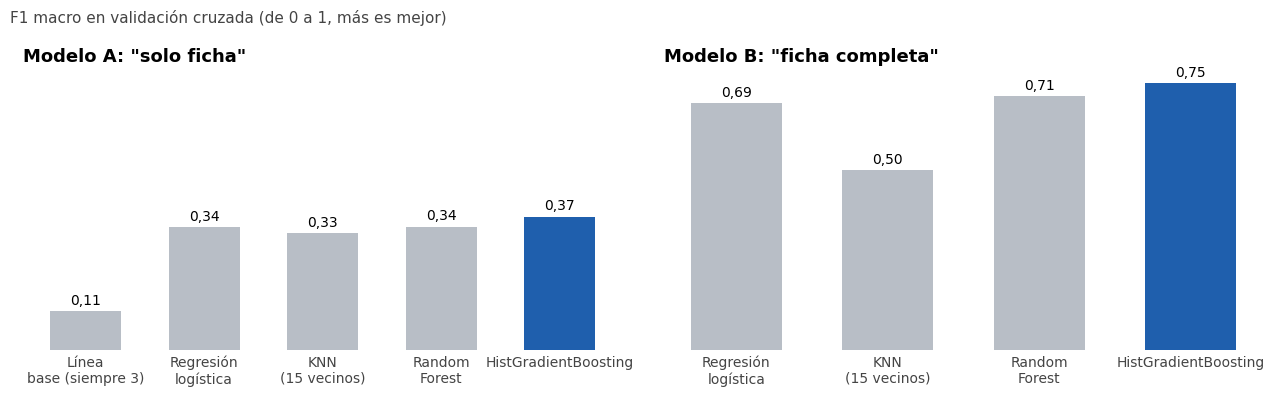

Accuracy  Acierto a 1 estrella  F1 macro
Versión Modelo                                                          
A       Línea base (siempre 3)     0.369                 0.828     0.108
        Regresión logística        0.425                 0.883     0.343
        KNN (15 vecinos)           0.398                 0.832     0.328
        Random Forest              0.443                 0.879     0.345
        HistGradientBoosting       0.439                 0.868     0.373
B       Regresión logística        0.703                 0.987     0.692
        KNN (15 vecinos)           0.563                 0.959     0.504
        Random Forest              0.727                 0.990     0.710
        HistGradientBoosting       0.754                 0.993     0.748

In [ ]:
pruebas = pd.DataFrame([
    # versión, modelo,                    accuracy, acierto a 1 estrella, F1 macro
    ("A", "Línea base (siempre 3)",          0.369, 0.828, 0.108),
    ("A", "Regresión logística",             0.425, 0.883, 0.343),
    ("A", "KNN (15 vecinos)",                0.398, 0.832, 0.328),
    ("A", "Random Forest",                   0.443, 0.879, 0.345),
    ("A", "HistGradientBoosting",            0.439, 0.868, 0.373),
    ("B", "Regresión logística",             0.703, 0.987, 0.692),
    ("B", "KNN (15 vecinos)",                0.563, 0.959, 0.504),
    ("B", "Random Forest",                   0.727, 0.990, 0.710),
    ("B", "HistGradientBoosting",            0.754, 0.993, 0.748),
], columns=["Versión", "Modelo", "Accuracy", "Acierto a 1 estrella", "F1 macro"]).set_index(["Versión", "Modelo"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, version, titulo in [(axes[0], "A", 'Modelo A: "solo ficha"'), (axes[1], "B", 'Modelo B: "ficha completa"')]:
    f1 = pruebas.loc[version, "F1 macro"]
    colores = [AZUL if v == f1.max() else GRIS for v in f1]              # destacamos el mejor
    barras = ax.bar([m.replace(" ", "\n", 1) for m in f1.index], f1, color=colores, width=0.6)
    ax.bar_label(barras, labels=[f"{v:.2f}".replace(".", ",") for v in f1], padding=3)
    ax.set_title(titulo)
    sin_ejes(ax)
fig.suptitle("F1 macro en validación cruzada (de 0 a 1, más es mejor)", fontsize=11, color="#444444", x=0.01, ha="left")
plt.tight_layout()
plt.show()

pruebas

Lo que sacamos de estas pruebas:

- **La línea base** (decir siempre 3 estrellas) acierta un 36,9 %, y a una estrella, un 82,8 % sin hacer nada, porque
  los fondos de 2, 3 y 4 estrellas están todos a una o menos del 3. Así que el acierto a una estrella hay que
  compararlo con ese 83 %, no con cero. Su F1 macro es 0,11, porque solo acierta una clase de cinco: por eso elegimos
  con el F1 macro.
- **Modelo A:** todos superan la línea base, pero sin alegrías (F1 de 0,33 a 0,37).
- **Modelo B:** el salto es enorme. Que la logística, un modelo lineal, ya saque un 0,69 nos dice que la relación es
  bastante "ordenada": cuanto mejor puesto en la categoría, más estrellas. KNN es el peor (0,50): con 134 columnas,
  la distancia entre fondos se reparte entre muchas columnas que no importan.
- **HistGradientBoosting es el mejor en los dos**, así que nos quedamos con él para A y para B.

**¿Y los hiperparámetros?** Probamos 20 combinaciones al azar con `RandomizedSearchCV` (como `GridSearchCV`, pero sin
probar todas). El F1 macro solo mejoró de 0,748 a 0,751 en el B y de 0,373 a 0,387 en el A. Son diferencias del
tamaño de lo que cambia el resultado de un trozo de la validación cruzada a otro (0,02), así que **dejamos los
hiperparámetros por defecto**, iguales para los dos modelos. La mejora del modelo B no vino de ajustar, sino de las
variables que elegimos en el apartado 2.

### 6.2 Cómo medimos

Las tres métricas del apartado 4. El "acierto a una estrella" no viene en scikit-learn, así que lo creamos nosotros y
lo convertimos en algo que entiende `cross_validate` con `make_scorer`.

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, accuracy_score, f1_score, confusion_matrix
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone

def acierto_una_estrella(y_real, y_pred):
    # % de fondos en los que fallamos como mucho por una estrella
    return np.mean(np.abs(np.asarray(y_real) - np.asarray(y_pred)) <= 1)

metricas = {
    "Accuracy": "accuracy",
    "Acierto a 1 estrella": make_scorer(acierto_una_estrella),
    "F1 macro": "f1_macro",
}

def crear_pipeline(version):
    preprocesador = crear_preprocesador(numericas_A if version == "A" else numericas_B)
    return Pipeline([("preprocesado", preprocesador),
                     ("modelo", HistGradientBoostingClassifier(random_state=42))])

### 6.3 Validación cruzada del modelo elegido

Antes de mirar el test, comprobamos con validación cruzada por cartera que el HistGradientBoosting da lo que dice la
tabla. Son 5 entrenamientos por modelo, menos de un minuto.

In [ ]:
validacion = {}
for version in ["A", "B"]:
    cv = cross_validate(crear_pipeline(version), X_train, y_train, groups=grupos_train,
                        cv=cv_grupos, scoring=metricas, n_jobs=-1)
    validacion[f"Modelo {version}"] = {m: f"{cv[f'test_{m}'].mean():.3f} ± {cv[f'test_{m}'].std():.3f}" for m in metricas}
pd.DataFrame(validacion)

,Modelo A,Modelo B
Accuracy,0.421 ± 0.023,0.743 ± 0.013
Acierto a 1 estrella,0.859 ± 0.015,0.993 ± 0.002
F1 macro,0.364 ± 0.026,0.732 ± 0.014


Sale lo mismo que en la tabla: un F1 macro de 0,37 en el modelo A y de **0,75** en el B, con una accuracy del 44 % y del **75 %**. El "±" es cuánto cambia el resultado de un trozo a otro: en los dos es pequeño (0,02), así que el modelo funciona parecido con cualquier grupo de carteras.

### 6.4 Entrenamiento y test

Ahora sí: entrenamos cada modelo **una sola vez** con todo train y, por primera y única vez, predecimos los 2.287
fondos del test, que no han visto nunca.

In [ ]:
modelos = {}
predicciones_test = {}
resultados_test = {}
for version in ["A", "B"]:
    modelos[version] = crear_pipeline(version).fit(X_train, y_train)
    pred = modelos[version].predict(X_test)
    predicciones_test[version] = pred
    resultados_test[f"Modelo {version}"] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Acierto a 1 estrella": acierto_una_estrella(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
    }
siempre_3 = np.full(len(y_test), 3)
resultados_test["Línea base (siempre 3)"] = {
    "Accuracy": accuracy_score(y_test, siempre_3),
    "Acierto a 1 estrella": acierto_una_estrella(y_test, siempre_3),
    "F1 macro": f1_score(y_test, siempre_3, average="macro"),
}
pd.DataFrame(resultados_test).round(3)

,Modelo A,Modelo B,Línea base (siempre 3)
Accuracy,0.468,0.785,0.376
Acierto a 1 estrella,0.891,0.992,0.841
F1 macro,0.416,0.782,0.109


En el test, que el modelo no había visto nunca:

- **Modelo B:** acierta las estrellas exactas en un **78,4 %** de los fondos, falla como mucho por una en un **99,5 %** y tiene un F1 macro de **0,77**.
- **Modelo A:** un 46,8 % exacto, un 88,3 % a una estrella y un F1 macro de 0,43.

Los dos salen incluso un poco mejor que en la validación cruzada (0,75 y 0,37 de F1). No es que hayan mejorado: el test son solo 685 carteras y hay algo de suerte en cuáles caen. Lo importante es que **no salen peor**: los modelos no se han aprendido train de memoria, y separar por cartera ha funcionado.

**¿Cuánto nos equivocamos cuando fallamos?** Contamos, para cada fondo del test, por cuántas estrellas ha fallado el
modelo.

Modelo A: falla por 2 o más estrellas en 253 de 2,322 fondos
Modelo B: falla por 2 o más estrellas en 19 de 2,322 fondos


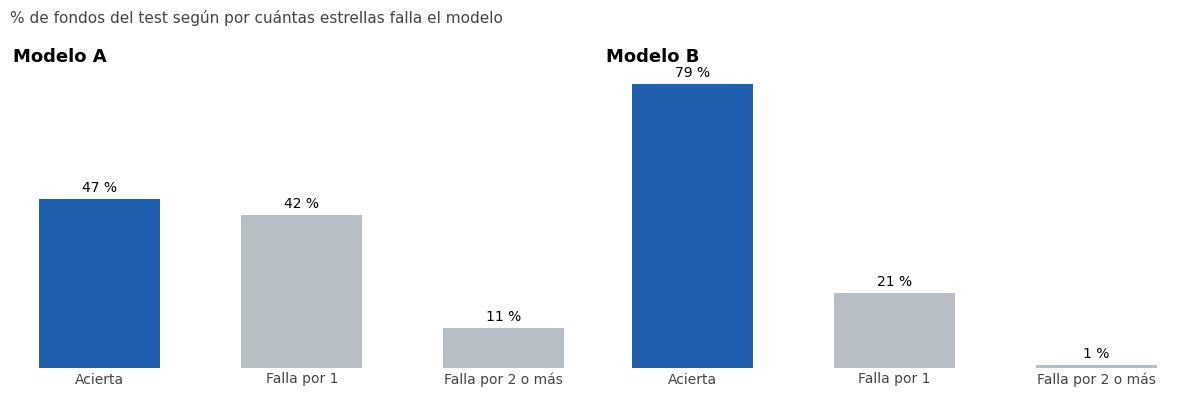

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, version in zip(axes, ["A", "B"]):
    distancia = np.abs(y_test.to_numpy() - predicciones_test[version])
    pct = pd.Series({"Acierta": (distancia == 0).mean(),
                     "Falla por 1": (distancia == 1).mean(),
                     "Falla por 2 o más": (distancia >= 2).mean()}) * 100
    barras = ax.bar(pct.index, pct, color=[AZUL, GRIS, GRIS], width=0.6)
    ax.bar_label(barras, labels=[f"{v:.0f} %" for v in pct], padding=3)
    ax.set_title(f"Modelo {version}")
    sin_ejes(ax)
    print(f"Modelo {version}: falla por 2 o más estrellas en {(distancia >= 2).sum()} de {len(distancia):,} fondos")
fig.suptitle("% de fondos del test según por cuántas estrellas falla el modelo", fontsize=11, color="#444444",
             x=0.01, ha="left")
plt.tight_layout()
plt.show()

Aquí está lo que queríamos demostrar. El modelo B acierta un 78 % y, del 22 % que falla, **los fallos son casi siempre de una sola estrella**: solo 11 de los 2.287 fondos del test (un 0,5 %) se llevan un error de dos estrellas o más. Si el modelo B dice que un fondo es de 4 estrellas, en el peor caso razonable será de 3 o de 5.

El modelo A falla más, pero tampoco a lo loco: un 41 % de los fondos por una estrella y un 12 % (267 fondos) por dos o más.

La **matriz de confusión** nos dice dónde están esos fallos. Cada fila son los fondos que de verdad tienen ese número de
estrellas, y cada casilla, qué % de ellos ha recibido cada predicción. Lo ideal es que todo esté en la diagonal.

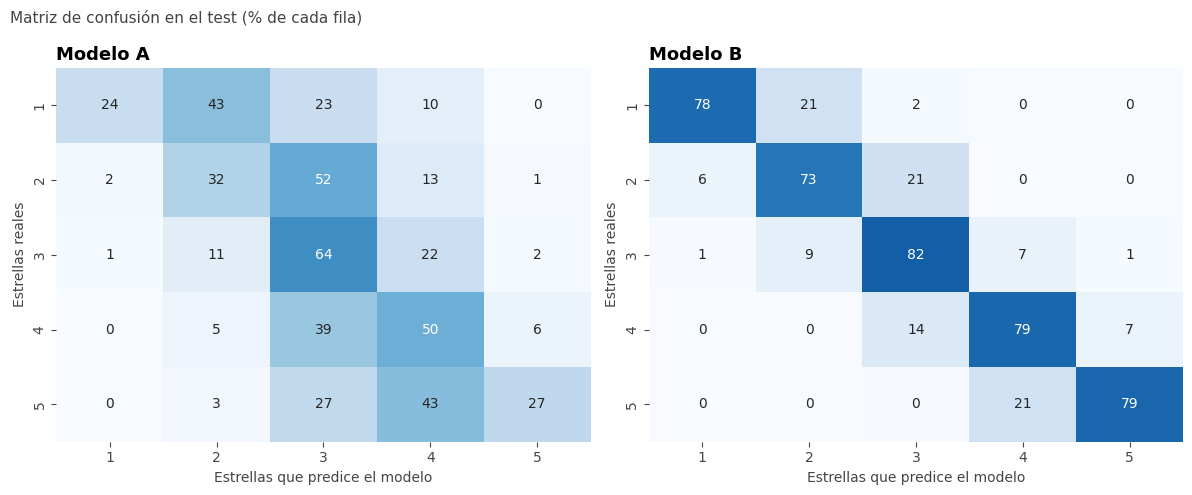

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, version in zip(axes, ["A", "B"]):
    matriz = confusion_matrix(y_test, predicciones_test[version], normalize="true") * 100   # % por fila
    sns.heatmap(matriz, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax,
                xticklabels=range(1, 6), yticklabels=range(1, 6), vmin=0, vmax=100)
    ax.set_title(f"Modelo {version}")
    ax.set_xlabel("Estrellas que predice el modelo")
    ax.set_ylabel("Estrellas reales")
fig.suptitle("Matriz de confusión en el test (% de cada fila)", fontsize=11, color="#444444", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**Modelo B:** la diagonal es fuerte (del 71 % al 84 % en cada clase) y casi todos los fallos están en las casillas de al lado. Donde más se confunde es en los extremos: un 28 % de los fondos de 5 estrellas se queda en 4, y un 27 % de los de 1 sube a 2. Tiene sentido: Morningstar corta por percentiles dentro de la categoría, y un fondo que está justo en el corte es casi imposible de distinguir del de al lado.

**Modelo A:** se refugia en el medio. Los fondos de 1 estrella solo los acierta un 27 % de las veces y los de 5, un 28 %; muchos se van al 3 o al 4. Aun así, casi nunca confunde un fondo de 1 con uno de 5.

### 6.5 Puntuamos los fondos sin estrellas

Ahora usamos el modelo para lo que lo construimos: **puntuar los 877 fondos que Morningstar todavía no ha puntuado**.

Como ya hemos medido con el test lo bien que funciona, reentrenamos el modelo con **todos** los fondos con estrellas,
train y test juntos: son 2.287 fondos más de los que aprender. `clone` copia el pipeline sin entrenar.

Usamos el **modelo A**, porque estos fondos casi no tienen historial. Comparamos el reparto de estrellas que les da con
el de los fondos que sí tienen.

Fondos sin estrellas con rentabilidad a 3 años: 19 de 877


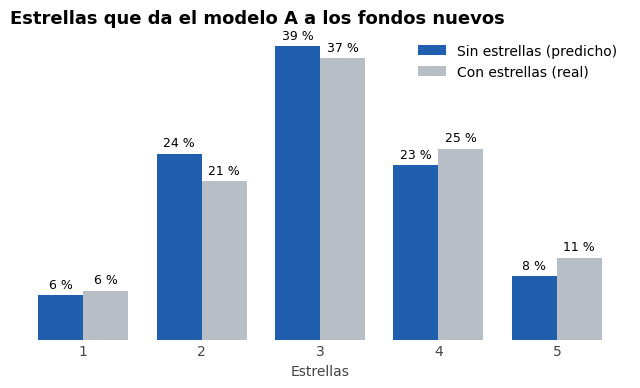

In [ ]:
tienen_historial = fondos_sin_estrellas["fund_return_3years"].notna()
print(f"Fondos sin estrellas con rentabilidad a 3 años: {tienen_historial.sum()} de {len(fondos_sin_estrellas)}")

modelo_final_A = clone(modelos["A"]).fit(X, y)
fondos_sin_estrellas["estrellas_predichas"] = modelo_final_A.predict(fondos_sin_estrellas[X.columns])

reparto = pd.DataFrame({
    "Sin estrellas (predicho)": fondos_sin_estrellas["estrellas_predichas"].value_counts(normalize=True),
    "Con estrellas (real)": y.value_counts(normalize=True),
}).reindex(range(1, 6)).fillna(0) * 100

fig, ax = plt.subplots(figsize=(8, 4))
ancho = 0.38
for desplazamiento, columna, color in [(-ancho / 2, reparto.columns[0], AZUL), (ancho / 2, reparto.columns[1], GRIS)]:
    barras = ax.bar(reparto.index + desplazamiento, reparto[columna], width=ancho, color=color, label=columna)
    ax.bar_label(barras, labels=[f"{v:.0f} %" for v in reparto[columna]], padding=3, fontsize=9)
ax.set_xticks(range(1, 6))
ax.set_xlabel("Estrellas")
ax.set_title("Estrellas que da el modelo A a los fondos nuevos")
ax.legend(frameon=False)
sin_ejes(ax)
plt.show()

Solo 19 de los 877 fondos sin estrellas tienen rentabilidad a 3 años, así que el modelo A era la única opción.

El reparto se parece bastante al de los fondos reales: un 38 % de 3 estrellas frente al 37 %, y muy parecido en 2 y 4. Donde más se aparta es en las 5 estrellas: se las da a un 5 % de los fondos nuevos, cuando entre los que tienen estrellas son un 11 %. Cuadra con la matriz de confusión: el modelo A se atreve poco con los extremos.

No podemos saber si acierta, porque Morningstar no ha puntuado estos fondos. Pero el test nos dice qué esperar: acertar las estrellas exactas en uno de cada dos fondos y quedarnos a una estrella en casi nueve de cada diez.

## 7. Conclusiones

Volvemos a la pregunta del principio: **¿cuánto se puede adivinar de las estrellas solo con la composición y los costes, y cuánto aporta conocer las rentabilidades pasadas?**

| En el test | Línea base | Modelo A (solo ficha) | Modelo B (ficha completa) |
|---|---|---|---|
| Accuracy | 37 % | 47 % | **78 %** |
| Acierto a una estrella | 83 % | 88 % | **99,5 %** |
| F1 macro | 0,11 | 0,43 | **0,77** |

- **Solo con la ficha se adivina algo, pero poco.** El modelo A mejora la línea base sobre todo gracias a la comisión y al tamaño: los fondos baratos y grandes tienen más estrellas. Sirve para hacerse una idea de un fondo nuevo, no para fiarse.
- **Con el historial, el modelo acierta casi 8 de cada 10.** Pero lo que da estrellas no es ganar mucho, sino ganar **más que los fondos de tu categoría**: el puesto en la categoría y la diferencia frente a ella son las columnas más relacionadas con las estrellas.
- **Cuando falla, falla por poco.** El modelo B se equivoca por dos estrellas o más solo en 11 de 2.287 fondos.
- **Separar por cartera era obligatorio.** El mismo fondo aparece en varias filas; sin separarlas, el modelo habría visto en train los fondos con los que luego lo evaluamos.

**Limitaciones:** el modelo B imita la fórmula de Morningstar con datos parecidos a los suyos, así que **no predice qué fondo va a ganar más en el futuro**: las estrellas miran hacia atrás, y nuestro modelo también. Y el modelo A ha aprendido con fondos viejos, así que no podemos comprobar si acierta con los nuevos.

**Con más tiempo** intentaríamos predecir las estrellas **del año siguiente**, que sí sería útil para invertir, aunque mucho más difícil.